# Geostatistics Athens Week project

Authors: *Ela Xiong, Aloyse Le, Mohamed Boudouh*

The notebook shows results ontained using several numerical methods (classical machine learning based , kriging) aiming to estimate mineral concentrations in a field using a finite number of empirical measurements.



In [ ]:
!pip install gstlearn[all]

In [ ]:
!pip install "git+https://github.com/mike-pereira/minigst.git@copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54#subdirectory=python"

  Cloning https://github.com/mike-pereira/minigst.git (to revision copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54) to /tmp/pip-req-build-mvoayrfj
  Running command git clone --filter=blob:none --quiet https://github.com/mike-pereira/minigst.git /tmp/pip-req-build-mvoayrfj
  Running command git checkout -b copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54 --track origin/copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54
  Switched to a new branch 'copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54'
  Branch 'copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54' set up to track remote branch 'copilot/fix-a88eb6a2-5304-4cf2-8999-189960bd6b54' from 'origin'.
  Resolved https://github.com/mike-pereira/minigst.git to commit b29d5087bfbdfd98edf0ef8de2852b78089a078a
  Installing build dependencies ... canceled
ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    st

Python packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import minigst  as mg
import gstlearn as gl
import gstlearn.plot as gp
import scipy as sc
np.random.seed(0)
## Figure sizes
plt.rcParams['figure.figsize'] = [8,6]

## The jura_all data set
The jura_all data set comprises seven heavy metals measured in the top soil of the swiss jura_all, along with consistently coded land use and rock type factors, as well as geographic coordinates.

Variable description :

* Xloc: X coordinate, local grid km
* Yloc: Y coordinate, local grid km
* Landuse: Land use: 1: Forest, 2: Pasture (Weide(land), Wiese, Grasland), 3: Meadow (Wiese, Flur, Matte, Anger), 4: Tillage (Ackerland, bestelltes Land)
* Rock: Rock Types: 1: Argovian, 2: Kimmeridgian, 3: Sequanian, 4: Portlandian, 5: Quaternary.
* Cd: mg cadmium kg^-1 topsoil
* Co: mg cobalt kg^-1 topsoil
* Cr: mg chromium kg^-1 topsoil
* Cu: mg copper kg^-1 topsoil
* Ni: mg nickel kg^-1 topsoil
* Pb: mg lead kg^-1 topsoil
* Zn: mg zinc kg^-1 topsoil

You are given three different files:

* jura_pred.csv: learning dataset
* jura_grid.csv: prediction grid (contains locations and covariables)
* jura_val_loc: validation locations and covariables

The dataframes on which we will be working on are:
* **grid**: *'Xloc', 'Yloc', 'Landuse", 'Rock'* information for nearly 5957 points. *Landuse* and *Rock* values are str.
* **jura_all**: the whole dataset. *Landuse* and *Rock* values have been replaced by their str counterparts and have been one-hot encoded to *'Landuse_Pasture', 'Landuse_Meadow', 'Landuse_Tillage','Rock_K', 'Rock_P', 'Rock_Q', 'Rock_S'*(see **II. Interpolation**)
* **jura**: the **training dataset**
* **val_loc**: *'Xloc', 'Yloc', 'Landuse', 'Rock'* of the **validation set**
* **val**: Cobalt (*'Co'*) concentration of the **validation set**
* **val_loc_k**: Kaggle validation locations (*'Xloc', 'Yloc', 'Landuse", 'Rock'*). *Landuse* and *Rock* values have been replaced by their str counterparts (see **Appendix**) and have been one-hot encoded (see **II. Interpolation**)

The databases on which we will be working on are:


*   **db_jura** : the gstlearn database of the whole dataset with *'Xloc'* and *'Yloc'* as coordinate variables
*   **db_jura_train** : the gstlearn database of the training dataset
*   **db_grid** : the gstlearn Grid Database containing the target grid for the predictions
*   **db_val** : the gstlearn database containing the validation locations and the value of Cobalt concentrations at those locations



## I. Exploratory analysis

### Basic statistics
1. load the dataset from jura_pred.csv (on the cloud)
2. What is the number of observations? What is the number of variables?
3. Compute the minimum and maximum value for each coordinate.
4. Compute basic statistics for the seven different heavy metals (mean, min, max, quartiles and standard deviation)
5. Compute the mean of cobalt concentration for the four different landuses

1. load the dataset from jura_all_pred.csv (on the cloud)

In [11]:
# Dataset
jura_all = pd.read_csv("jura_pred.csv")
# Prediction grid
grid = pd.read_csv("jura_grid.csv")
# Kaggle validation locations
val_loc_k=pd.read_csv("jura_val_loc.csv")

2. What is the number of observations? What is the number of variables?


In [4]:
jura_all.shape

(259, 11)

We have 259 observations and 11 variables.

3. Compute the minimum and maximum value for each coordinate.

In [8]:
## Here are two ways to compute the minimum of each coordinate
res= [jura_all['Xloc'].min(), jura_all['Yloc'].min()]
print("\n Min - 1st way :\n ", res)

res=jura_all[['Xloc','Yloc']].min(0)
print("\n Min - 2nd way :\n", res)

## Likewise for the maximum
res=[jura_all['Xloc'].max(), jura_all['Yloc'].max()]
print("\n Max - 1st way :\n", res)

res=jura_all[['Xloc','Yloc']].max(0)
print("\n Max - 2nd way :\n", res)


 Min - 1st way :
  [np.float64(0.626), np.float64(0.58)]

 Min - 2nd way :
 Xloc    0.626
Yloc    0.580
dtype: float64

 Max - 1st way :
 [np.float64(4.92), np.float64(5.69)]

 Max - 2nd way :
 Xloc    4.92
Yloc    5.69
dtype: float64


4. Compute basic statistics for the seven different heavy metals (mean, min, max, quartiles and standard deviation)

In [6]:
## Using the describe method of Pandas dataframes
res=jura_all.iloc[:,4:].describe()

print(res)

               Cd          Co          Cr          Cu          Ni          Pb  \
count  259.000000  259.000000  259.000000  259.000000  259.000000  259.000000   
mean     1.309077    9.302579   35.070116   23.727490   19.730347   53.916602   
std      0.915188    3.576046   10.957509   20.712635    8.232858   29.792158   
min      0.135000    1.552000    8.720000    3.960000    4.200000   18.960000   
25%      0.637500    6.520000   27.440000   11.020000   13.800000   36.520000   
50%      1.070000    9.760000   34.840000   17.600000   20.560000   46.400000   
75%      1.715000   11.980000   42.220000   27.820000   25.420000   60.400000   
max      5.129000   17.720000   67.600000  166.400000   53.200000  229.560000   

               Zn  
count  259.000000  
mean    75.078301  
std     29.019291  
min     25.200000  
25%     55.000000  
50%     73.560000  
75%     89.920000  
max    219.320000  


5. Compute the mean cobalt concentration for the four different landuses

In [ ]:
mean_Co_1=jura_all['Co'][jura_all['Landuse']==1].mean()
mean_Co_2=jura_all['Co'][jura_all['Landuse']==2].mean()
mean_Co_3=jura_all['Co'][jura_all['Landuse']==3].mean()
mean_Co_4=jura_all['Co'][jura_all['Landuse']==4].mean()
print([mean_Co_1,mean_Co_2,mean_Co_3,mean_Co_4])

[np.float64(7.694545454545455), np.float64(10.064285714285713), np.float64(9.393866666666666), np.float64(8.372000000000002)]


### Graphical Representations
1. Plot the points in the dataset using their coordinates 'Xloc' and 'Yloc'.
2. On the same plot, display the points with landuse 2 (pasture) in red.
3. Plot the seven heavy metal concentrations histograms.
4. Plot the seven heavy metal concentrations as functions of the landuse (boxplots)
5. Plot the seven heavy metal concentrations as functions of the rocktype (boxplots)

1. Plot the points in the dataset using their coordinates 'Xloc' and 'Yloc'.

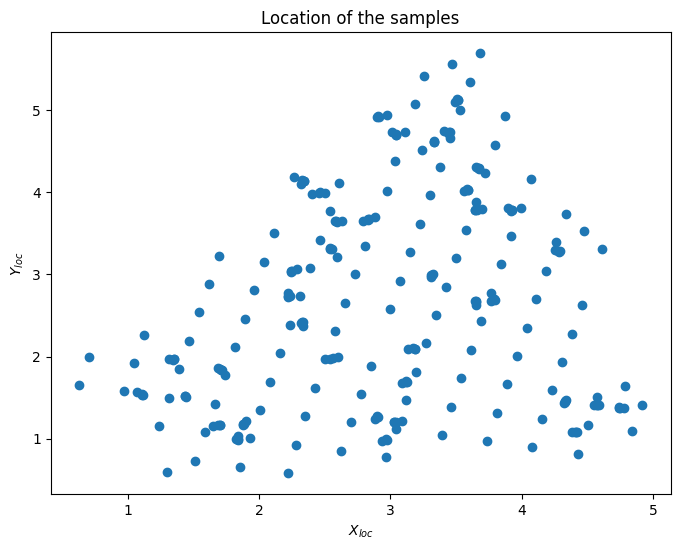

In [ ]:
plt.plot(jura_all['Xloc'], jura_all['Yloc'], 'o')
plt.xlabel('$X_{loc}$')
plt.ylabel('$Y_{loc}$')
plt.title('Location of the samples')
plt.show()

2. On the same plot, display the points with landuse 2 (pasture) in red.

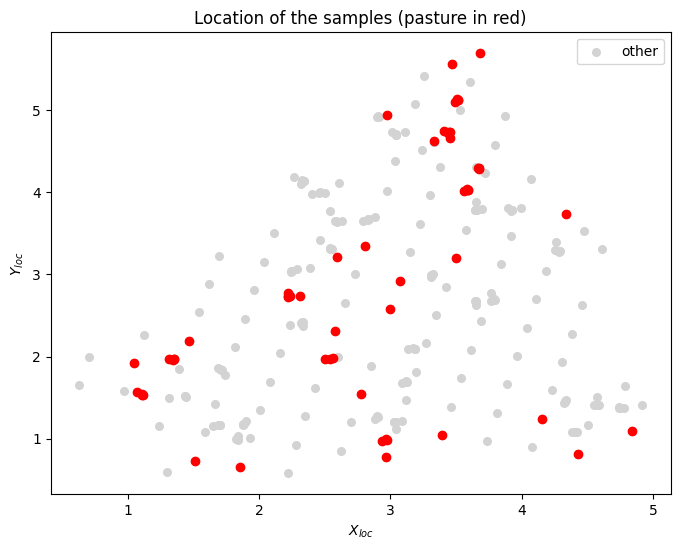

In [ ]:
plt.scatter(jura_all['Xloc'], jura_all['Yloc'], c='lightgray', label='other', s=30)
plt.scatter(jura_all['Xloc'][jura_all['Landuse']==2],jura_all['Yloc'][jura_all['Landuse']==2],color="red")
plt.xlabel('$X_{loc}$')
plt.ylabel('$Y_{loc}$')
plt.title('Location of the samples (pasture in red)')
plt.legend()
plt.show()

3. Plot the seven heavy metal concentrations histograms.


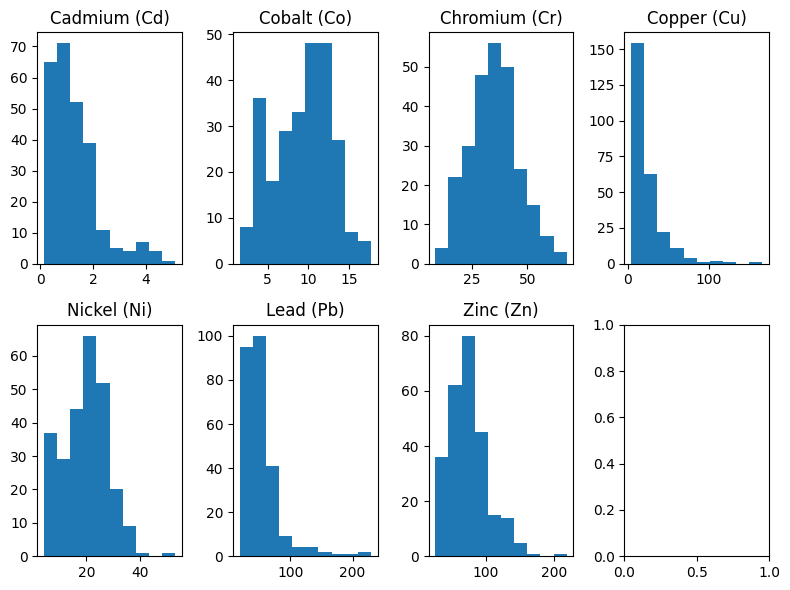

In [ ]:
fig,ax = plt.subplots(nrows=2, ncols=4)
ax[0,0].hist(jura_all['Cd'])
ax[0,0].set_title('Cadmium (Cd)')
ax[0,1].hist(jura_all['Co'])
ax[0,1].set_title('Cobalt (Co)')
ax[0,2].hist(jura_all['Cr'])
ax[0,2].set_title('Chromium (Cr)')
ax[0,3].hist(jura_all['Cu'])
ax[0,3].set_title('Copper (Cu)')
ax[1,0].hist(jura_all['Ni'])
ax[1,0].set_title('Nickel (Ni)')
ax[1,1].hist(jura_all['Pb'])
ax[1,1].set_title('Lead (Pb)')
ax[1,2].hist(jura_all['Zn'])
ax[1,2].set_title('Zinc (Zn)')
plt.tight_layout()
plt.show()

The Cobalt distribution is very beautiful, it looks like a gaussian one. That is why we choose to work with this heavy metal.

4. Plot the seven heavy metal concentrations as functions of the landuse (boxplots)

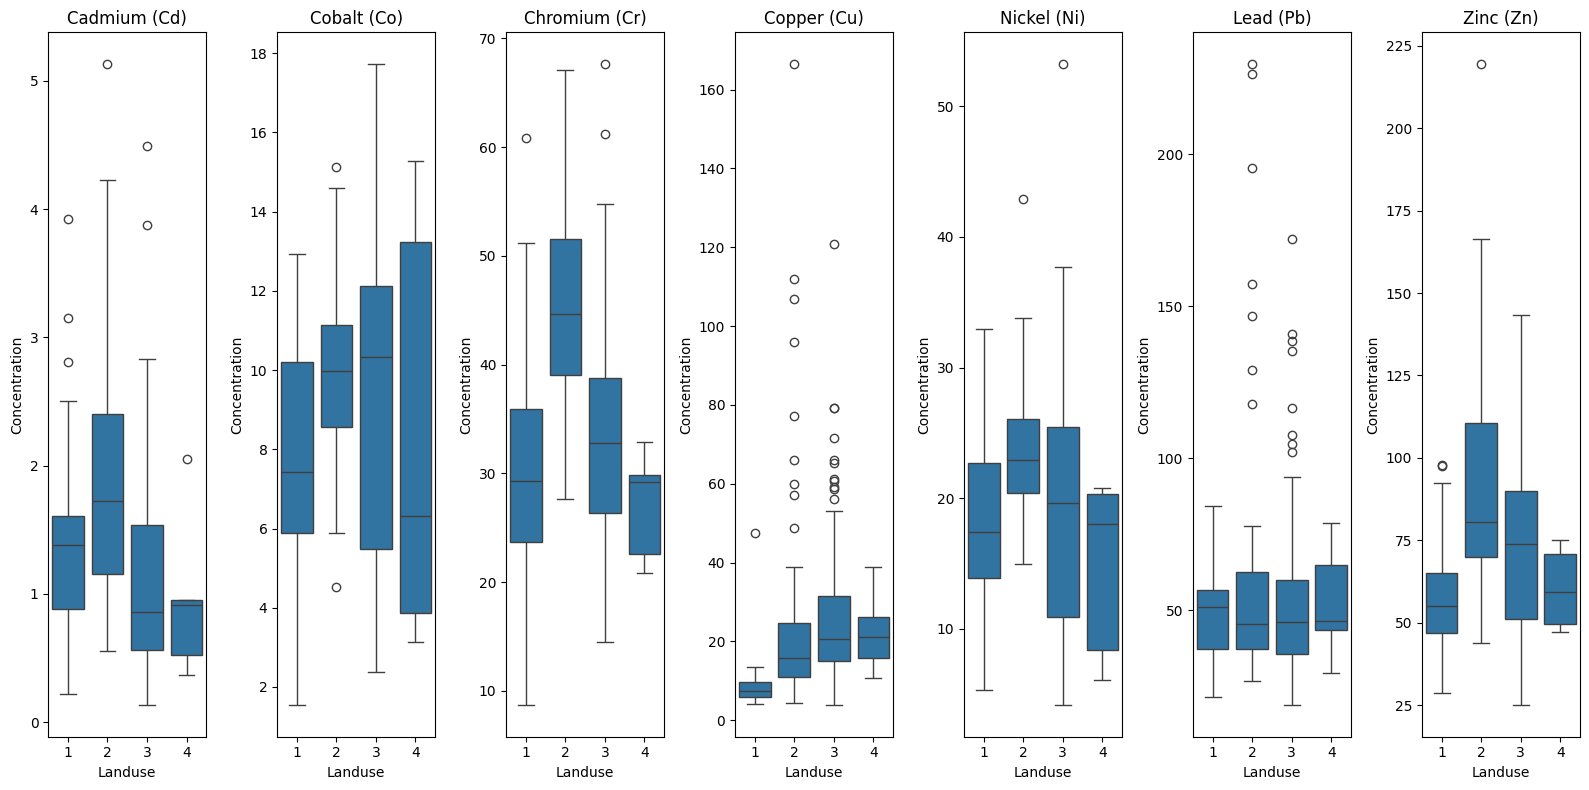

In [ ]:
metal_names = ['Cadmium (Cd)', 'Cobalt (Co)', 'Chromium (Cr)', 'Copper (Cu)', 'Nickel (Ni)', 'Lead (Pb)', 'Zinc (Zn)']
# use actual dataframe column names for the metal values
metal_cols = ['Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']

fig, ax = plt.subplots(nrows=1, ncols=len(metal_names), figsize=(16,8))
for i, col in enumerate(metal_cols):
    sns.boxplot(x=jura_all['Landuse'], y=jura_all[col], ax=ax[i])
    ax[i].set_title(metal_names[i])
    ax[i].set_xlabel('Landuse')
    ax[i].set_ylabel('Concentration')
plt.tight_layout()
plt.show()

We have to keep in mind that there are unfortunately significantly less values for Landscape 4.

5. Plot the seven heavy metal concentrations as functions of the rocktype (boxplots)

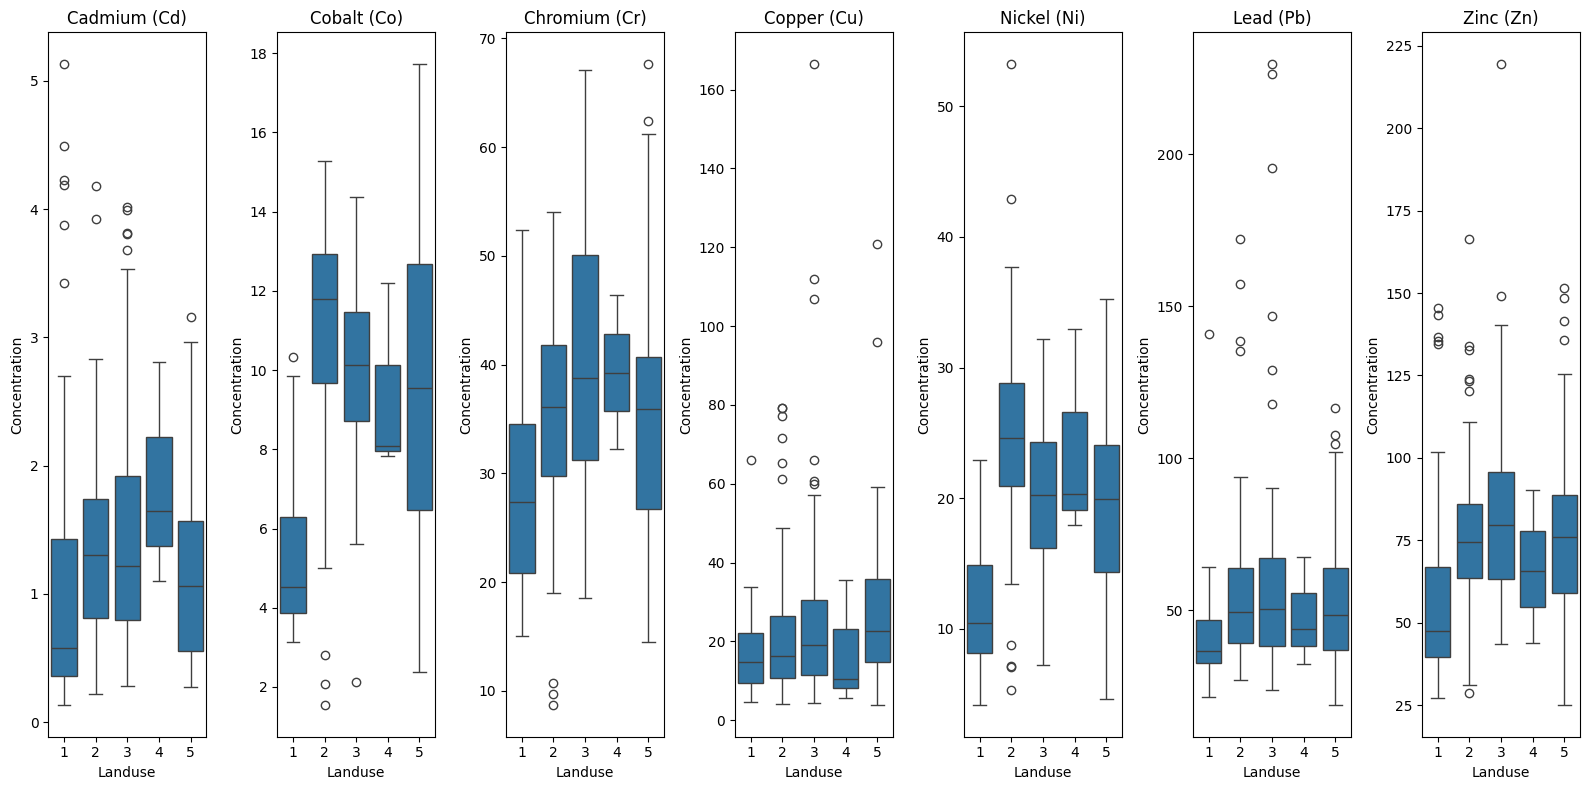

In [ ]:
metal_names = ['Cadmium (Cd)', 'Cobalt (Co)', 'Chromium (Cr)', 'Copper (Cu)', 'Nickel (Ni)', 'Lead (Pb)', 'Zinc (Zn)']
# use actual dataframe column names for the metal values
metal_cols = ['Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']

fig, ax = plt.subplots(nrows=1, ncols=len(metal_names), figsize=(16,8))
for i, col in enumerate(metal_cols):
    sns.boxplot(x=jura_all['Rock'], y=jura_all[col], ax=ax[i])
    ax[i].set_title(metal_names[i])
    ax[i].set_xlabel('Landuse')
    ax[i].set_ylabel('Concentration')
plt.tight_layout()
plt.show()

We have to keep in mind that there are unfortunately significantly less values for Rock 4.

### Some statistics
1. Perform an ANOVA analysis on the Cobalt concentrations with Landuse, Rock and the interactions. Comment the results.
2. Do the same on the other concentrations (check the histograms prior to apply a transformation if necessary).


1. Perform an ANOVA analysis on the Cobalt concentrations with Landuse, Rock and the interactions. Comment the results.

To perform a linear regression with categorical variables, we use the *ols* function from the *statsmodels* package.

In [ ]:
## For linear regressions (using R-style formulas to define regression)
from statsmodels.formula.api import ols

In [ ]:
# Fit the regression model
model_aov = ols(formula='Co ~  C(Landuse) + C(Rock) + C(Landuse * Rock)', data=jura_all).fit()
print(model_aov.summary())

                            OLS Regression Results                            
Dep. Variable:                     Co   R-squared:                       0.439
Model:                            OLS   Adj. R-squared:                  0.406
Method:                 Least Squares   F-statistic:                     13.62
Date:                Sun, 23 Nov 2025   Prob (F-statistic):           1.05e-23
Time:                        18:58:02   Log-Likelihood:                -622.26
No. Observations:                 259   AIC:                             1275.
Df Residuals:                     244   BIC:                             1328.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

To perform an ANOVA analysis, we use the *stats.anova_lm* function from the *statsmodels* package.

In [ ]:
## For ANOVA regressions
from statsmodels.api import stats

In [ ]:
# Perform anova analysis
anova_table = stats.anova_lm(model_aov)
print(anova_table)

                      df       sum_sq     mean_sq          F        PR(>F)
C(Landuse)           3.0   123.526414   41.175471   5.424769  1.254118e-03
C(Rock)              4.0  1154.120573  288.530143  38.013153  1.036294e-24
C(Landuse * Rock)   10.0   186.825845   18.682585   2.461386  8.065145e-03
Residual           244.0  1852.026209    7.590271        NaN           NaN


Comment on the results:
The first column shows the degree of freedom. The second column is the sum of squares and measures the total amount of variation in the predicted variable that is explained by each factor (explicative variable or interaction). The third column is the mean square and is used to calculate F (it standarzises sum_sq to compare explicative variables between each other). The fourth column is the test statistic. It measures the variation due to the factor. The estimated parameters for this anova model are 5.424769 for Landuse, 38.013153 for Rock and 2.461386 for the interaction between the two. The last column of the table above is the p value for the nullity test of the coefficients. It is the probability to get the F value if the factor had no effect. It is inferior to 0.05 for the three factors, so **htese three factors have a statistically significant effect on the predicted variable**, the **Rock** parameter having a particularly strong effect.

2. Do the same on the other concentrations (check the histograms prior to apply a transformation if necessary).

ANOVA is a model that uses assumptions on the data. ANOVA assumes that it follows a **gaussian lineary model**. We'll look at the histogramms to ensure this.
The histogramms for **Cd, Cu, Ni, Pb and Zn** do **not correspond to a gaussian model**. We'll try to perform a log transformation and see what the histograms look like after that.

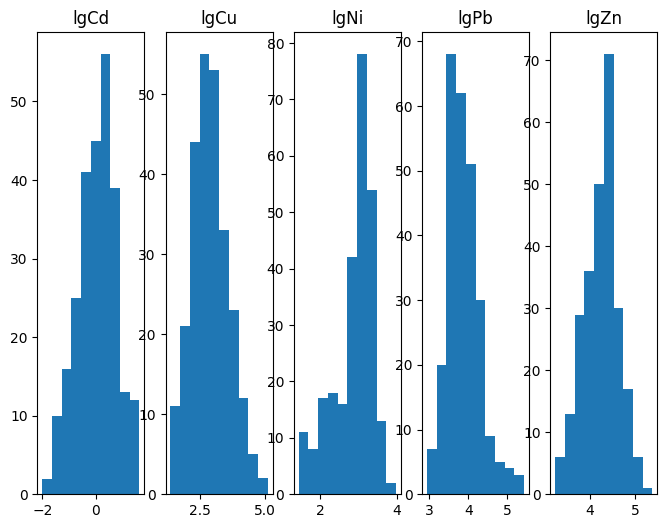

In [ ]:
# Perform the log transformation
lgCd=np.log(jura_all['Cd'])
lgCu=np.log(jura_all['Cu'])
lgNi=np.log(jura_all['Ni'])
lgPb=np.log(jura_all['Pb'])
lgZn=np.log(jura_all['Zn'])

# Plot on a grid
fig,ax = plt.subplots(nrows=1,ncols=5) ## To create a grid of plots
ax[0].hist(lgCd)
ax[0].set_title('lgCd')
ax[1].hist(lgCu)
ax[1].set_title('lgCu')
ax[2].hist(lgNi)
ax[2].set_title('lgNi')
ax[3].hist(lgPb)
ax[3].set_title('lgPb')
ax[4].hist(lgZn)
ax[4].set_title('lgZn')
plt.show()

The transformation gives more satisfying results. We will work with these log variables for the anova.

In [ ]:
for heavy_metal_col_name in ['lgCd','Cr','lgCu','lgNi','lgPb','lgZn']:
  # Fit the regression model
  model_aov = ols(formula=f'{heavy_metal_col_name} ~  C(Landuse) + C(Rock) + C(Landuse * Rock)', data=jura_all).fit()
  print(model_aov.summary())
  # Perform anova analysis
  anova_table = stats.anova_lm(model_aov)
  print(anova_table)

                            OLS Regression Results                            
Dep. Variable:                   lgCd   R-squared:                       0.272
Model:                            OLS   Adj. R-squared:                  0.230
Method:                 Least Squares   F-statistic:                     6.509
Date:                Sun, 23 Nov 2025   Prob (F-statistic):           3.86e-11
Time:                        18:58:04   Log-Likelihood:                -236.75
No. Observations:                 259   AIC:                             503.5
Df Residuals:                     244   BIC:                             556.8
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

The anova results indicate that Landuse is a highly significant factor of lgCd, Cr, lgCu, lgNi. Rock is a highly significant factor all the heavy metals. The interaction Landuse:Rock is a highly significant factor of lgCd, Cr, lgCNi, lgZn.

Significant factors for each heavy metal:
lgCd: Landuse, Rock, interaction Landuse:Rock
Cr: Landuse, Rock, interaction Landuse:Rock
lgCu: Landuse, Rock
lgNi: Landuse, Rock, interaction Landuse:Rock
lgPb: Rock
lgZn: Rock, interaction Landuse:Rock


## II. Interpolation

Provide the maps of the cobalt concentration over the Swiss jura_all obtained with several regression/interpolation methods, e.g.:


* anova
* linear regression on the coordinates
* Random Forests
* Nearest neighbours
* Inverse distance
* ...


Let's change the names of Landuse and Rock in order to be consistent with their names on the grid.

In [ ]:
## Replace landuse interger code by name
landuse_codes=[1,2,3,4]
landuse_names=["Forest","Pasture","Meadow","Tillage"]
jura_all["Landuse"]=jura_all["Landuse"].replace(landuse_codes,landuse_names)
val_loc_k["Landuse"]=val_loc_k["Landuse"].replace(landuse_codes,landuse_names)

## Replace rock type integer code by name
rock_codes=[1,2,3,4,5]
rock_names=["Argovian","Kimmeridgian","Sequanian","Portlandian","Quaternary"]
jura_all["Rock"]=jura_all["Rock"].replace(rock_codes,rock_names)
val_loc_k["Rock"]=val_loc_k["Rock"].replace(rock_codes,rock_names)

Let's one-hot encode *'Landuse'* and *'Rock'*, as attributing integers to their values would be arbitrary.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Landuse one-hot
enc_lu = OneHotEncoder(handle_unknown='ignore', drop='first')
enc_lu.fit(jura_all[["Landuse"]])
lu_newnames = ["Landuse_Pasture", "Landuse_Meadow", "Landuse_Tillage"]
lu_indic_jura = pd.DataFrame(enc_lu.transform(jura_all[["Landuse"]]).toarray(), columns=lu_newnames, index=jura_all.index)
jura_all = pd.concat([jura_all, lu_indic_jura], axis=1)
lu_indic_grid = pd.DataFrame(enc_lu.transform(grid[["Landuse"]]).toarray(), columns=lu_newnames, index=grid.index)
grid = pd.concat([grid, lu_indic_grid], axis=1)
lu_indic_val_loc_k = pd.DataFrame(enc_lu.transform(val_loc_k[["Landuse"]]).toarray(), columns=lu_newnames, index=val_loc_k.index)
val_loc_k = pd.concat([val_loc_k, lu_indic_val_loc_k], axis=1)

# Rock one-hot
enc_rock = OneHotEncoder(handle_unknown='ignore', drop='first')
enc_rock.fit(jura_all[["Rock"]])
rock_newnames = ["Rock_K", "Rock_P", "Rock_Q", "Rock_S"]
rock_indic_jura = pd.DataFrame(enc_rock.transform(jura_all[["Rock"]]).toarray(), columns=rock_newnames, index=jura_all.index)
jura_all = pd.concat([jura_all, rock_indic_jura], axis=1)
rock_indic_grid = pd.DataFrame(enc_rock.transform(grid[["Rock"]]).toarray(), columns=rock_newnames, index=grid.index)
grid = pd.concat([grid, rock_indic_grid], axis=1)
rock_indic_val_loc_k = pd.DataFrame(enc_rock.transform(val_loc_k[["Rock"]]).toarray(), columns=rock_newnames, index=val_loc_k.index)
val_loc_k = pd.concat([val_loc_k, rock_indic_val_loc_k], axis=1)

# Combined list of new indicator names
newnames = rock_newnames + lu_newnames

Let's separate the data into two sets: the training set (jura_all_train) and the validation set (jura_all_validation).

In [ ]:
ntot = jura_all.shape[0]
ntrain = 200
nval = ntot - ntrain

indtrain = np.random.choice(ntot,ntrain,replace=False).astype(int)
indval = np.setdiff1d(np.arange(ntot),indtrain)

jura =jura_all.loc[indtrain,:]

#val contains the values to predict. For the project, these values will be on Kaggle
#(for other locations) and you won't know them
#You will have the locations and covariables at the unknown locations by the following command :
val_loc = jura_all.loc[indval,['Xloc','Yloc','Landuse','Rock'] + newnames]
val = jura_all.loc[indval,['Co']]

To be able to plot a variable on the grid, we use the following code.

In [ ]:
### Prepare grid data for plotting
xgrid = np.unique(grid["Xloc"])
ygrid = np.unique(grid["Yloc"])

# Create meshgrid for plotting
nx = len(xgrid)
ny = len(ygrid)

## Function to plot a variable on the grid
def plot_grid_variable(var, grid_df, name, figsize=(10, 8)):
    """
    Plot a variable on the grid using matplotlib

    Parameters:
    - var: array of values to plot
    - grid_df: DataFrame containing grid information with 'Xloc' and 'Yloc'
    - name: name of the variable for the title
    - figsize: size of the figure
    """
    # Get unique x and y coordinates
    xvals = np.unique(grid_df["Xloc"])
    yvals = np.unique(grid_df["Yloc"])

    # Create 2D array for plotting
    nx = len(xvals)
    ny = len(yvals)
    Z = np.full((ny, nx), np.nan)

    # Fill the 2D array with values
    for i, (x, y, v) in enumerate(zip(grid_df["Xloc"], grid_df["Yloc"], var)):
        ix = np.where(xvals == x)[0][0]
        iy = np.where(yvals == y)[0][0]
        Z[iy, ix] = v

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(Z, extent=[xvals.min(), xvals.max(), yvals.min(), yvals.max()],
                   origin='lower', aspect='equal', cmap='viridis')
    ax.set_xlabel('Xloc')
    ax.set_ylabel('Yloc')
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label=name)
    plt.tight_layout()
    return fig, ax

### Anova

To perform a linear regression with categorical variables (*Landuse* and *Rock*), we use the *ols* function from the *statsmodels* package.

In [ ]:
## For linear regressions (using R-style formulas to define regression)
from statsmodels.formula.api import ols

# Fit the regression model (on the training set)
model_aov = ols(formula='Co ~  Landuse + Rock + Landuse * Rock', data=jura).fit()
print(model_aov.summary())

                            OLS Regression Results                            
Dep. Variable:                     Co   R-squared:                       0.495
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     11.23
Date:                Sun, 23 Nov 2025   Prob (F-statistic):           7.57e-20
Time:                        18:58:06   Log-Likelihood:                -469.09
No. Observations:                 200   AIC:                             972.2
Df Residuals:                     183   BIC:                             1028.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

We don't need the C() function here because *Landuse* and *Rock* are already categorical variables as we converted them to strings ealier.

To perform an ANOVA analysis, we use the *stats.anova_lm* function from the *statsmodels* package.

In [ ]:
# For ANOVA regressions
from statsmodels.api import stats

# Perform anova analysis
anova_table = stats.anova_lm(model_aov)
print(anova_table)

                 df       sum_sq     mean_sq          F        PR(>F)
Landuse         3.0    74.562844   24.854281   3.565004  1.529697e-02
Rock            4.0   932.571454  233.142863  33.441125  6.237449e-21
Landuse:Rock   12.0   250.543931   20.878661   2.994756  7.550160e-04
Residual      183.0  1275.828617    6.971741        NaN           NaN


We can see that the p-values for *Landuse*, *Rock*, and their interaction are all less than $0.05$, indicating that these factors significantly affect the Cobalt concentration. Therefore, they are good Cobalt concentration predictors. However, the ANOVA assumes that the residuals are independently and normally distributed with constant variance, which is not the case here. Indeed, points which are spatially close will have similar residuals, violating the independence assumption.

Let's visualize the predictions of the ANOVA method on the grid.

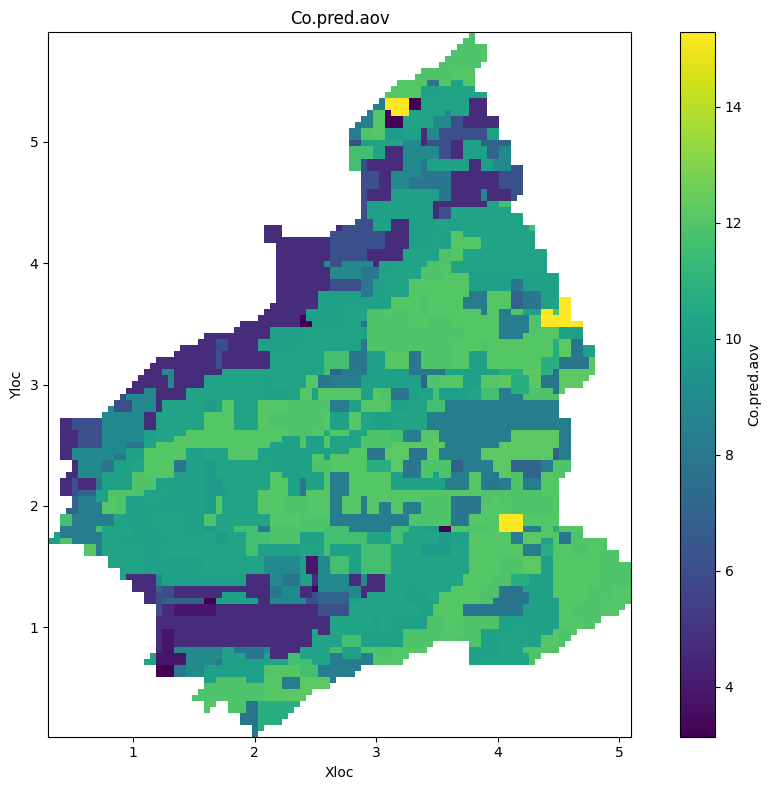

In [ ]:
# Prediction on the grid
res_aov = model_aov.predict(grid)

## Plot results
plot_grid_variable(res_aov, grid, "Co.pred.aov")
plt.show()

Let's estimate the MSE of the ANOVA model.

In [ ]:
#Prediction on the validation locations
res_val_aov=model_aov.predict(val_loc)

#Compute score
print("MSE : ",np.mean((res_val_aov-val['Co'])**2))

MSE :  8.576441758361353


### Linear regression of functions of coordinates

To perform a coordinate-based linear regression, we use the *ols* function from the *statsmodels* package once again.

In [ ]:
# Fit the linear regression  model
model_trend = ols(formula='Co~Xloc+Yloc+Xloc*Yloc+Xloc**2+Yloc**2', data=jura).fit()
model_trend.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     Co   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     14.01
Date:                Sun, 23 Nov 2025   Prob (F-statistic):           2.60e-08
Time:                        18:58:07   Log-Likelihood:                -518.05
No. Observations:                 200   AIC:                             1044.
Df Residuals:                     196   BIC:                             1057.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.3192      1.762      5.858      0.000       6.845      13.793
Xloc           0.3520      0.546      0.645      0.520      -0.725       1.429
Yloc          -2.2067      0.824     -2.677      0.008      -3.832      -0.581
Xloc:Yloc      0.4791      0.251      1.912      0.057      -0.015       0.973
==============================================================================
Omnibus:                        4.743   Durbin-Watson:                   2.231
Prob(Omnibus):                  0.093   Jarque-Bera (JB):                3.859
Skew:                          -0.237   Prob(JB):                        0.145
Kurtosis:                       2.512   Cond. No.                         90.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

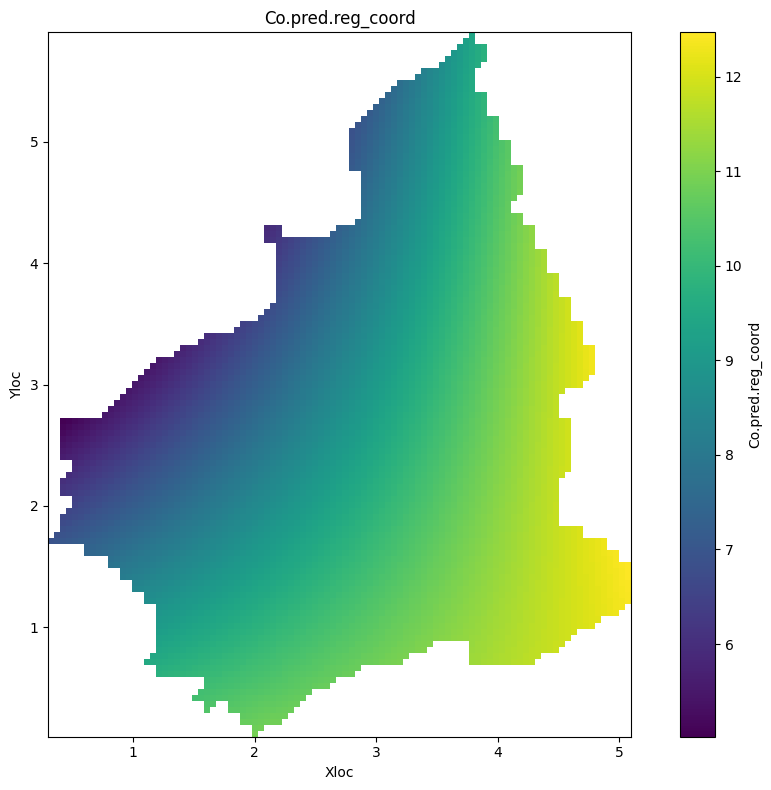

In [ ]:
## Prediction on the grid
res_trend = model_trend.predict(grid)

## Plot results
plot_grid_variable(res_trend, grid, "Co.pred.reg_coord")
plt.show()

The predictions are overly smooth. Let's estimate the MSE of this method.

In [ ]:
#Prediction on the validation locations
res_val_trend=model_trend.predict(val_loc)

#Compute score
print("MSE : ",np.mean((res_val_trend-val['Co'])**2))

MSE :  12.19682317560037


The MSE value of this method is quite high. The predictions are overly smooth. Indeed, *'Landuse'* and *'Rock'* are not taken into account in this model, contrary to ANOVA, which results seem better.

### Random Forests

In [ ]:
## Random forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint
import os

#Optimization of hyperparameters
param_dist = {
    'n_estimators': randint(100, 1000),
    'max_depth': [None] + list(range(5, 31, 5)),
    'min_samples_split': randint(2, 11),
    'min_samples_leaf': randint(1, 5),
    'max_features': ['auto', 'sqrt', 0.3, 0.5, 0.8]
}

# Avoid KMeans/MKL memory leak on Windows by limiting OpenMP threads
os.environ.setdefault("OMP_NUM_THREADS", "2")

coords = jura[['Xloc','Yloc']].to_numpy()
n_groups = 10
kmeans = KMeans(n_clusters=n_groups, random_state=0).fit(coords)
groups = kmeans.labels_

gkf = GroupKFold(n_splits=5)

rf = RandomForestRegressor(random_state=0)

rs = RandomizedSearchCV(rf, param_distributions=param_dist, n_iter=50,
                        scoring='neg_mean_squared_error', cv=gkf.split(jura[['Xloc','Yloc'] + newnames], jura['Co'], groups=groups), n_jobs=-1, random_state=0, verbose=2)
rs.fit(jura[['Xloc','Yloc'] + newnames], jura['Co'])
best_rf = rs.best_estimator_

## Fit model
best_rf.fit(jura[['Xloc','Yloc'] + newnames], jura['Co'])

## Prediction on the grid
res_rf = best_rf.predict(grid[['Xloc','Yloc'] + newnames])
## Plot results
plot_grid_variable(res_rf, grid, "Co.pred.rf")
plt.show()

## Prediction on the validation locations
res_val_rf = best_rf.predict(val_loc[['Xloc','Yloc'] + newnames])

## Compute score
print("MSE : ",np.mean((res_val_rf-val['Co'])**2))

Fitting 5 folds for each of 50 candidates, totalling 250 fits


The obtained MSE value is lower than for the ANOVA and the linear regression of functions of coordinates.

#### Gradient Boosting Trees (XGBoost)

We do the same thing as before but instead of using RandomForestRegressor, we use XGBoostRegressor.

In [ ]:
# XGBoost regression
from xgboost import XGBRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint
import os

# Optimization of hyperparameters
param_dist_xgb = {
    'n_estimators': randint(100, 1000),
    'max_depth': [3, 5, 7, 9, 12],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'subsample': [0.5, 0.7, 0.9, 1.0],
    'colsample_bytree': [0.3, 0.5, 0.7, 1.0],
    'min_child_weight': randint(1, 10),
    'gamma': [0, 0.1, 0.2, 0.5, 1.0]
}

# Avoid KMeans/MKL memory leak on Windows by limiting OpenMP threads
os.environ.setdefault("OMP_NUM_THREADS", "1 ")

coords = jura[['Xloc','Yloc']].to_numpy()
n_groups = 10
kmeans = KMeans(n_clusters=n_groups, random_state=0).fit(coords)
groups = kmeans.labels_

gkf = GroupKFold(n_splits=5)

xgb = XGBRegressor(objective='reg:squarederror', random_state=0, n_jobs=-1, verbosity=0)

rs_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring='neg_mean_squared_error',
    cv=gkf.split(jura[['Xloc','Yloc'] + newnames], jura['Co'], groups=groups),
    n_jobs=-1,
    random_state=0,
    verbose=2
)

# Tune
rs_xgb.fit(jura[['Xloc','Yloc'] + newnames], jura['Co'])
best_xgb = rs_xgb.best_estimator_

# Fit best model
best_xgb.fit(jura[['Xloc','Yloc'] + newnames], jura['Co'])

# Predict on grid and plot
res_xgb = best_xgb.predict(grid[['Xloc','Yloc'] + newnames])
plot_grid_variable(res_xgb, grid, "Co.pred.xgb")
plt.show()

# Predict on validation and compute MSE
res_val_xgb = best_xgb.predict(val_loc[['Xloc','Yloc'] + newnames])
print("MSE : ", np.mean((res_val_xgb - val['Co'])**2))


### Nearest Neighbors

To perform nearest neighbors regression, we use the *KNeighborsRegressor* function from the *scikit-learn* package. We also have to choose the number of neighbors to consider. Therefore, we try here all values between 1 and 20 and we compute the MSE for each of them.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

errors = []
for n in range(20):
    model_knn = KNeighborsRegressor(n_neighbors=n+1)
    model_knn.fit(jura[['Xloc','Yloc']], jura['Co'])
    res_val_knn = model_knn.predict(val_loc[['Xloc','Yloc']])

    mse = np.mean((res_val_knn - val['Co'])**2)
    errors.append(mse)
    print("n_neighbors =", n+1, "MSE :", mse)

# Find best number of neighbors (lowest MSE)
errors = np.array(errors)
best_idx = int(np.argmin(errors))
best_n = best_idx + 1
print("\nBest n_neighbors:", best_n, "with MSE:", errors[best_idx])

# Plot MSE vs neighbors and mark best
plt.plot(range(1,21), errors, marker='o')
plt.axvline(best_n, color='red', linestyle='--', label=f'Best n={best_n}')
plt.xlabel('Number of neighbours')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [ ]:
## Fit model
model_knn = KNeighborsRegressor(n_neighbors=best_n)
model_knn.fit(jura[['Xloc','Yloc']], jura['Co'])

## Prediction on the grid
res_knn = model_knn.predict(grid[['Xloc','Yloc']])

## Plot results
plot_grid_variable(res_knn, grid, "Co.pred.knn")
plt.show()

We are conscious that the *best_n* predicted depends on how the training and validation sets were split, and it may vary with different random seeds.

### Inverse distance

To perform inverse distance regression, we use the *RadiusNeighborsRegressor* function from the *scikit-learn* package.

In [ ]:
## Radius neighbors regression
from sklearn.neighbors import RadiusNeighborsRegressor

## Fit model
model_invdist = RadiusNeighborsRegressor(radius=10,weights='distance') ## Take a big radius to include all points
model_invdist.fit(jura[['Xloc','Yloc']], jura['Co'])

## Prediction on the grid
res_invdist = model_invdist.predict(grid[['Xloc','Yloc']])

## Plot results
plot_grid_variable(res_invdist, grid, "Co.pred.invdist")
plt.show()

Let's estimate the MSE of this inverse distance regression method.

In [ ]:
## Prediction on the validation locations
res_val_invdist=model_invdist.predict(val_loc[['Xloc','Yloc']])

## Compute score
print("MSE : ",np.mean((res_val_invdist-val['Co'])**2))

The MSE is quite high.

## III. Univariate analysis (using minigst)

### III.1 Variography

#### Experimental variogram (isotropic case)

1. Compute and plot the experimental variogram of the cobalt concentration. Try different values of lag and comment the results.
2. Print the number of pairs of points used to compute the variogram values for different values of lag and comment the results.

In [33]:
## Create databse
db_jura= mg.df_to_db(jura_all, coord_names = ["Xloc", "Yloc"])

In [34]:
## Display database
db_jura.display()


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 19
Total number of samples      = 259

Variables
---------
Column = 0 - Name = Xloc - Locator = x1
Column = 1 - Name = Yloc - Locator = x2
Column = 2 - Name = Landuse - Locator = NA
Column = 3 - Name = Rock - Locator = NA
Column = 4 - Name = Cd - Locator = NA
Column = 5 - Name = Co - Locator = NA
Column = 6 - Name = Cr - Locator = NA
Column = 7 - Name = Cu - Locator = NA
Column = 8 - Name = Ni - Locator = NA
Column = 9 - Name = Pb - Locator = NA
Column = 10 - Name = Zn - Locator = NA
Column = 11 - Name = Rock_K - Locator = NA
Column = 12 - Name = Rock_P - Locator = NA
Column = 13 - Name = Rock_Q - Locator = NA
Column = 14 - Name = Rock_S - Locator = NA
Column = 15 - Name = Landuse_F - Locator = NA
Column = 16 - Name = Landuse_P - Locator = NA
Column = 17 - Name = Landuse_M - Locator = NA
Column = 18 - Name = Landus

In [14]:
## Create experimental variogram object with specified parameters
varioexp = mg.vario_exp(db_jura,vname="Co",nlag=20, dlag=0.1, toldis = .5)

In [15]:
## Display result
varioexp.display()


Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 2
Variable(s)                 = [Co]

Variance-Covariance Matrix    12.739

Direction #1
------------
Number of lags              = 20
Direction coefficients      =      1.000     0.000
Direction angles (degrees)  =      0.000
Tolerance on direction      =     90.000 (degrees)
Calculation lag             =      0.100
Tolerance on distance       =     50.000 (Percent of the lag value)

For variable 1
      Rank    Npairs  Distance     Value
         0   193.000     0.024     1.766
         1   155.000     0.104     2.815
         2   249.000     0.206     4.326
         3   414.000     0.297     6.563
         4   644.000     0.391     7.582
         5   692.000     0.496     8.661
         6   538.000     0.601     9.514
         7   755.000     0.700    10.969
         8   916.000     0.800    11.624
         9   709.000     0.896    12.155
        10   931.000     

In [ ]:
# Plot the experimental variogram
gp.plot(varioexp, showPairs = True)

In [ ]:
## Try with different values of toldis regarding dlag: studying lag overlaping
# Loop the computing of the variogram
for k in [0.01,0.05, 0.5]:
  ## Create experimental variogram object with specified parameters
  varioexp = mg.vario_exp(db_jura,vname="Co",nlag=20, dlag=0.1, toldis = k)
  ## Plot the experimental variogram
  gp.plot(varioexp, showPairs=True)
  ## Display grid
  plt.show()

**Question 1:**
Trying different values for the tolerance of the lags (toldis) regarding dlag: The **smaller** the lag tolerance (ie the smaller the lag wideness), the **rougher** the curve. On the first curve, the tolerance is smaller than dlag/2, so there are **"holes"** (points which aren't used in the copmputation). On the second curve, the tolerance equals dlag/2, so there are no holes, and the lags fit perfectly, they do not overlap. On the third curve, the lags **overlap**, which makes the curve **smooth** because lags next to another share points which are used to compute their center.

**Question 2:**
Looking at the number of pairs used we can see that there are fewer on the first plot (6 to 164) than the last (155 to 1370). The number of pairs used increases with toldis, which is coherent given the fact that toldis defines the wideness of each lag (so there are more pairs used when the lag is wide).

In [ ]:
# Try different values of lags

## Try with different values of nlag
# Loop the computing of the variogram
for k in [10, 20, 60]:
  ## Create experimental variogram object with specified parameters
  varioexp = mg.vario_exp(db_jura,vname="Co",nlag=k, dlag=0.1, toldis = .5)
  ## Plot the experimental variogram
  gp.plot(varioexp, showPairs=True)
  ## Display grid
  plt.show()


**Question 1:**
Trying different number of lags (nlag):
Here we have dlag/2 = toldis so the lag don't overlap and there are no holes.
For a small nlag, we don't go far in the values of the distance between the points, we only look at points which are geographically near to each other. For a large nlag, we go further and we can look at points which are far away from each other.

**Question 2:**
Here since the lags don't overlap we can see exactly how many pairs are in each section of the plot. The last graph shows that there are very few pairs at a high distance (2 pairs with a distance > 5), which is coherent. There seem to be many pairs between distances of 1 and 3.

#### Experimental variogram (anisotropic case)

1. Compute and plot the variogram maps of the Cobalt concentration to check for anisotropies. Comment.
2. Compute and plot directional variograms (according to the anisotropy directions determined with the maps).

1. Compute and plot the variogram maps of the Cobalt concentration to check for anisotropies. Comment.

In [ ]:
## Compute variogram map
grid_vmap = mg.vario_map(db_jura,"Co",20)
import matplotlib.pyplot as plt
## Plot (Left: Variogram map, Right: Number of pairs used to compute each value)
fig, ax = plt.subplots(1,2,figsize=[14,10])
fig.tight_layout(pad=5.0)
ax[0].raster(grid_vmap,flagLegend=True)
ax[1].raster(grid_vmap, name="*Nb",flagLegend = True)
plt.show()

We can see different axes upon which the variance changes at a different speed. These are anisotropies. The longer axis to reach the sill is at 45° and the shorter axis to reach the sill is at 135°.

2. Compute and plot directional variograms (according to the anisotropy directions determined with the maps).

In [ ]:
## Create experimental variogram parametrization:
vario_2dir = mg.vario_exp(db_jura, vname = "Co",dir = [45,135],nlag=30, dlag=0.1, toldis=0.5)

In [ ]:
## Plot
ax = gp.varmod(vario_2dir, flagLegend=True)

#### Model adjustement

1. Adjust a model (isotropic and anisotropic cases) on experimental variograms and print the model caracteristics.
2. Try imposing different structures or combinations of structures.

### **Isotropic case**

In [ ]:
## Create experimental variogram object with specified parameters
vario_iso = mg.vario_exp(db_jura,vname="Co",nlag=20, dlag=0.1, toldis = .5)

In [ ]:
# isotropic case
model_iso=mg.model_fit(vario_iso,struct=["NUGGET","EXPONENTIAL"])

In [ ]:
ax = gp.varmod(vario_iso, model_iso)

In [ ]:
model_iso

#### Adjusting the isotropic model
We'll create a function to fit and plot models with different structures on the same plot. The legend shows the experimental model for each structure in dashed lines, but it is the same for each structure (we just weren't able to get rid of them).

Here are the structures we will test:


In [ ]:
list_struct_names_exp = [["NUGGET"], ["EXPONENTIAL"], ["NUGGET", "EXPONENTIAL"]]
list_struct_names_spherical = [["SPHERICAL"], ["NUGGET","SPHERICAL"],["NUGGET", "EXPONENTIAL", "SPHERICAL"]]
list_struct_names_cubic = [["CUBIC"], ["NUGGET","CUBIC"],["NUGGET", "EXPONENTIAL", "CUBIC"], ["NUGGET", "SPHERICAL", "CUBIC"]]

In [ ]:
# Create a function to fit and plot modelswith different structures on the same plot
def model_fit_and_plot(varioexp, list_struct_names):
    color_list = ["C0", "C1", "C2", "C3", "C4", "C5"]
    i=0
    for struct_names in list_struct_names:
        model_iso=mg.model_fit(varioexp,struct=struct_names)
        ax = gp.varmod(varioexp, model_iso, color=color_list[i], label=str(struct_names), flagLegend=True)
        print(model_iso)
        i+=1


Testing the nugget and exponential structures:

In [ ]:
model_fit_and_plot(vario_iso, list_struct_names_exp)

**Comment :** On this plot, we can see that the nugget effect enables the curve to begin at approximately 1.8 instead of zero. The 'nugget' + 'exponential' model seems to fit better.

Testing the spherical structure:

In [ ]:
model_fit_and_plot(vario_iso, list_struct_names_spherical)

**Comment:** We can see that as with the exponential model, the nugget allows us to begin higher than zero. The *'nugget' + 'spherical'* curve overlaps with the *'nugget' + 'spherical'+'exponential'* curve. Moreover, the model characteristics for the *'nugget' + 'spherical'+'exponential'* structures show that the sill for the *'exponential'* structure is zero. Therefore, we can think that the *'exponential'* structure doesn't add anything to our *'nugget' + 'spherical'* model.
Comparing the *'nugget' + 'spherical'* and the *'nugget' + 'exponential'* model, it seems that the first one is more relevant (fits the experimental variogram better), at least on the part of the variogram we observe (distances going from 0 to 2). The *'nugget' + 'spherical'* model has a lower sill (14.015) and seems to reach its sill faster.

**Testing the Cubic model**

In [ ]:
model_fit_and_plot(vario_iso, list_struct_names_cubic)

**Comment:** We can see that the *cubic* and *nugget+cubic* models don't seem to fit very well because they start slowly (at distance zero), whereas our experimental variogram starts increase fast (furthermore the *nugget+cubis* has a -1 optimization return code which signals that the structures aren't adapted). The *nugget+exponential+cubic* and *nugget+spherical+cubic* models seem to fit well. They are very similar.

**Anisotropic model**

In [ ]:
## Create Model object and fit the experimental variogram
model_2dir = mg.model_fit(vario_2dir, ["NUGGET","EXPONENTIAL"])

In [ ]:
## Plot
ax = gp.varmod(vario_2dir, model_2dir)

In [ ]:
model_2dir

Adjusting the anisotropic model

In [ ]:
model_fit_and_plot(vario_2dir, list_struct_names_exp)

### III.2 Prediction

#### Ordinary Kriging

1. Compute and plot the ordinary kriging of the cobalt over the prediction grid. Plot the associated standard deviation map.
2. Try several variogram models (basic structures, anisotropy), and neighborhood options. Compute the prediction scores. Comment the results.


First, we create a gstlearn database containing the data points, and assign the appropriate locators to the variables. The gstlearn database created in section III.1 contains all the data points, whereas the one we use in this section contains only the training data points. We will call it db_jura_train to differenciate the two.

In [35]:
## Create Db containing the training data
db_jura_train=mg.df_to_db(jura,["Xloc","Yloc"])

## Display content
db_jura_train.display()

NameError: name 'jura' is not defined

We then create a gstlearn Grid Database containing the target grid for the prediction.

In [36]:
## Create DbGrid that covers the Db containing the data
db_grid= mg.df_to_dbgrid(grid, ["Xloc","Yloc"])
db_grid.display()


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 13
Total number of samples      = 11349

Grid characteristics:
---------------------
Origin :      0.300     0.100
Mesh   :      0.050     0.050
Number :         97       117

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = Xloc - Locator = x1
Column = 2 - Name = Yloc - Locator = x2
Column = 3 - Name = Landuse - Locator = NA
Column = 4 - Name = Rock - Locator = NA
Column = 5 - Name = Rock_K - Locator = NA
Column = 6 - Name = Rock_P - Locator = NA
Column = 7 - Name = Rock_Q - Locator = NA
Column = 8 - Name = Rock_S - Locator = NA
Column = 9 - Name = Landuse_F - Locator = NA
Column = 10 - Name = Landuse_P - Locator = NA
Column = 11 - Name = Landuse_M - Locator = NA
Column = 12 - Name = Landuse_T - Locator = z1


We then create a Db containing the validation locations and the value of Cobalt concentrations at those locations.

In [37]:
## Create Db
db_val=mg.df_to_db(val_loc, ["Xloc","Yloc"])
db_val.display()

NameError: name 'val_loc' is not defined

In [ ]:
## Compute kriging on target grid
mg.minikriging(db_jura_train,db_grid, model = fitmod, vname = "Co", prefix = "OK")

## Compute kriging on validation locations
mg.minikriging(db_jura_train,db_val, model = fitmod, vname = "Co", prefix = "OK")


In [ ]:
## Plot prediction
im=gp.plot(db_grid, "OK.Co.estim")
gp.plot(db_jura_train, c='black',s=1)
plt.title("Ordinary Kriging prediction")
plt.axis("equal")
plt.colorbar(im)
plt.show()

## Plot kriging standard-deviation
im = gp.plot(db_grid, "OK.Co.stdev")
gp.plot(db_jura_train, c='black', s = 5)
plt.title("Ordinary Kriging standard-deviation")
plt.axis("equal")
plt.colorbar(im)
plt.show()

In [ ]:
## Compute RMSE
rmse_OK=np.mean((val["Co"]-db_val["OK*estim"])**2)**0.5
print("RMSE=",rmse_OK)

## Compute MAPE
mape_OK=np.mean(abs((val["Co"]-db_val["OK*estim"])/val["Co"]))
print("MAPE=",mape_OK)

2. Try several variogram models (basic structures, anisotropy), and neighborhood options. Compute the prediction scores. Comment the results.

Exploring basic structures

In [ ]:
# Create the different models
## Isotropic models
# the 'nugget'+'exponential' isotropic model is the model_iso variable defined above
model_nugget_spherical=mg.model_fit(varioexp,struct=["NUGGET", "SPHERICAL"])
model_exponential=mg.model_fit(varioexp,struct=["EXPONENTIAL"])

## Anisotropic models
model_dir_nugget_exponential = mg.model_fit(vario_dir, ["NUGGET","EXPONENTIAL"])
model_dir_nugget_spherical = mg.model_fit(vario_dir, ["NUGGET","SPHERICAL"])


In [ ]:
# Create function that computes the kriging, plots and RMSE and MAPE scores
def kriging_plot_score(model):
    ## Compute kriging on target grid
    mg.minikriging(db_jura_train,db_grid, model = model, vname = "Co", prefix = "OK")

    ## Compute kriging on validation locations
    mg.minikriging(db_jura_train,db_val, model = model, vname = "Co", prefix = "OK")

    ## Plot prediction
    im=gp.plot(db_grid, "OK.Co.estim")
    gp.plot(db_jura_train, c='black',s=1)
    plt.title("Ordinary Kriging prediction")
    plt.axis("equal")
    plt.colorbar(im)
    plt.show()

    ## Plot kriging standard-deviation
    im = gp.plot(db_grid, "OK.Co.stdev")
    gp.plot(db_jura_train, c='black', s = 5)
    plt.title("Ordinary Kriging standard-deviation")
    plt.axis("equal")
    plt.colorbar(im)
    plt.show()

    ## Compute RMSE
    rmse_OK=np.mean((val["Co"]-db_val["OK*estim"])**2)**0.5
    print("RMSE=",rmse_OK)

    ## Compute MAPE
    mape_OK=np.mean(abs((val["Co"]-db_val["OK*estim"])/val["Co"]))
    print("MAPE=",mape_OK)

In [ ]:
kriging_plot_score(model_nugget_spherical)

**Comment:** The *'nugget'+'spherical'* model is highly similar to the *'nugget'+'exponential'* model. However, the standard deviation for the first one is slightly lower. Furthermore, the RMSE is lower too (2.0262932677720022 compared to 2.0850030393720265) so *'nugget'+'spherical'* seems to be a better model.

In [ ]:
kriging_plot_score(model_exponential)

The RMSE is higher for the *'exponential'* model than the *'nugget' + 'exponential'* and '*'nugget'+'spherical* models.

**Anisotropic models**

In [ ]:
kriging_plot_score(model_dir_nugget_exponential)

**Comment:** The RMSE of this anisotropic *'nugget'+'exponential'* (2.0722650470464656) model is lower than for the isotropic *'nugget'+'exponential'* (2.0850030393720265)

In [ ]:
kriging_plot_score(model_dir_nugget_spherical)

**Comment:** The RMSE of this anisotropic *'nugget'+'spherical'* model is lower than the anisotropic *'nugget'+'exponential'* above, but higher than the isotropic *'nugget'+'spherical'* (2.0262932677720022). This is odd because for the *'nugget'+'exponential'* above, the anisotropic case worked way better.

#### Universal kriging

Use the indicators of the different levels of the categorical variables (*Rock*,*Landuse* and the interactions) as covariates to compute the universal kriging prediction.

1. Define a model with a constant mean (*order = 0*) and the number of variables with a f locator the we want to work with (*nfex = 4*).
2. Compute the variogram of the residuals.
3. Adjust a model on the variogram of the residuals. Do not forget to set the drift functions.
4. Compute the Kriging with external drift prediction on the grid as well as the standard deviation map.

In [38]:
jura_all, grid, _ = mg.data("Jura")

We Change the names of the Land Use and Rock in order to be consistent with their names on the grid

In [39]:
## Replace landuse interger code by name
landuse_codes=[1,2,3,4]
landuse_names=["Forest","Pasture","Meadow","Tillage"]
jura_all["Landuse"]=jura_all["Landuse"].replace(landuse_codes,landuse_names)

## Replace rock type integer code by name
rock_codes=[1,2,3,4,5]
rock_names=["Argovian","Kimmeridgian","Sequanian","Portlandian","Quaternary"]
jura_all["Rock"]=jura_all["Rock"].replace(rock_codes,rock_names)

We Build the predictor variables corresponding to Rock with one-hot encoding

In [66]:
from sklearn.preprocessing import OneHotEncoder
# drop the first column for each feature
enc = OneHotEncoder(handle_unknown='ignore',drop='first')
enc.fit(jura_all[["Rock"]])
newnames = ["Rock_K","Rock_P","Rock_Q","Rock_S"]
rock_indic_jura = pd.DataFrame(enc.transform(jura_all[["Rock"]]).toarray(),columns = newnames)
jura_all = pd.concat([jura_all,rock_indic_jura],axis=1)
rock_indic_grid = pd.DataFrame(enc.transform(grid[["Rock"]]).toarray(),columns = newnames)
grid = pd.concat([grid,rock_indic_grid],axis=1)

We Build the predictor variables corresponding to landuse with one-hot encoding

In [61]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown='ignore')
enc.fit(jura_all[["Landuse"]])
newnames =["Landuse_F","Landuse_P","Landuse_M","Landuse_T"]
landuse_indic_jura = pd.DataFrame(enc.transform(jura_all[["Landuse"]]).toarray(),columns = newnames)
jura_all = pd.concat([jura_all,landuse_indic_jura],axis=1)
landuse_indic_grid = pd.DataFrame(enc.transform(grid[["Landuse"]]).toarray(),columns = newnames)
grid = pd.concat([grid,landuse_indic_grid],axis=1)

## Variography of the residuals

We compute the variogram of the residuals

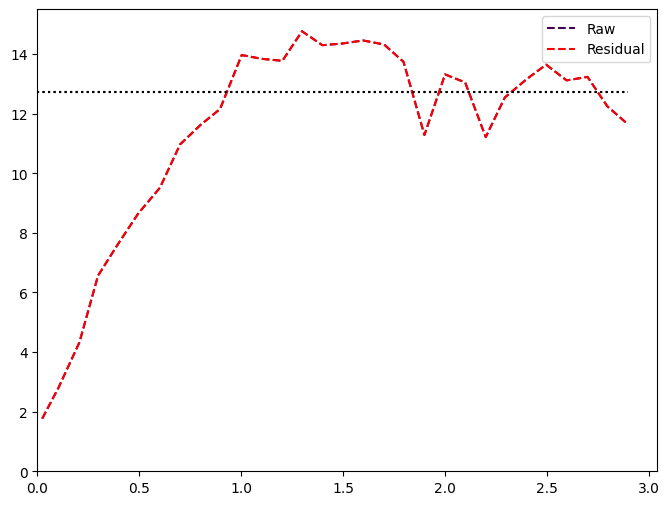

In [21]:
#Vario of the residuals
varioResiduals = mg.vario_exp(db_jura, vname= "Co", ext_drift= ["Rock_*","Landuse_*"], nlag = 30, dlag = 0.1, toldis = 0.5)


#Vario of the raw variable for comparison
varioRaw = mg.vario_exp(db_jura, vname= "Co", nlag = 30, dlag = 0.1, toldis = 0.5)


## Plot
ax = gp.varmod(varioRaw,showPairs=False,label = "Raw")
ax = gp.varmod(varioResiduals,showPairs=False,color = "r",label = "Residual")
ax = plt.legend()

Model fitting

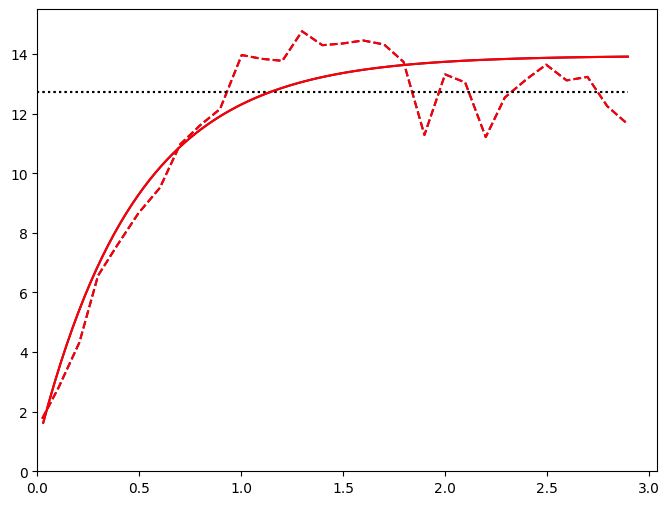

In [65]:
fitmodRaw = mg.model_fit(varioRaw, struct = ["NUGGET","EXPONENTIAL"])
fitmodResiduals = mg.model_fit(varioResiduals, struct = ["NUGGET","EXPONENTIAL"])

## Plot
gp.varmod(varioResiduals, fitmodResiduals)
gp.varmod(varioRaw, fitmodRaw,color="r")
plt.show()

Computing kriging's result

The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The retu

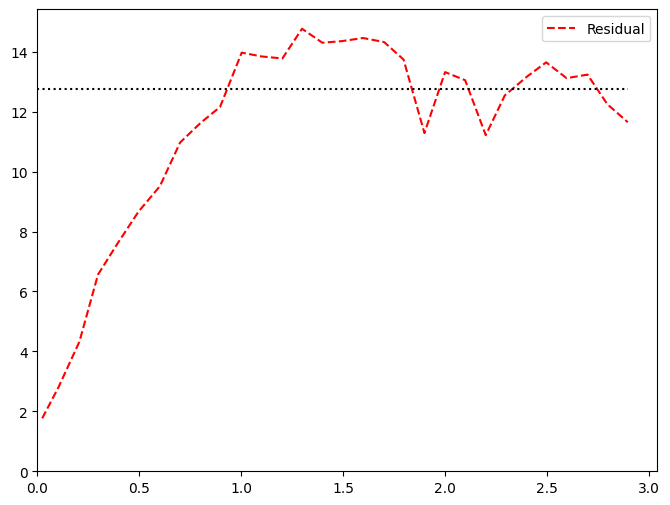

In [64]:
## Compute kriging
err = mg.minikriging(db_jura,db_grid, vname = "Co", ext_drift= ["Rock_*" ,"Landuse_*"], model = fitmodResiduals, prefix = "KED")

## Compute ordinary kriging for comparison
err = mg.minikriging(db_jura,db_grid, vname = "Co", model = fitmodRaw, prefix = "OK")
ax = gp.varmod(varioResiduals,showPairs=False,color = "r",label = "Residual")
ax = plt.legend()

## IV. Multivariate analysis (using minigst)

### IV.1 Fitting a multivariate model

1. Compute the  empirical directional variograms and covariograms of a carefully chosen (justify) set of variables.

Let's compute the empirical variograms and covariograms of the metals which are the most correlated to *Co*.

In [ ]:
# Correlation to pick candidate continuous auxiliaries
metals = ['Co','Pb','Zn','Cu','Ni','Cd','Cr']
corr = jura[metals].corr()['Co'].abs().sort_values(ascending=False)
print(corr)

We can see that *Ni* is the most correlated with *Co* (after *Co* itself). That is why we will use choose the set of variables ['Co', 'Ni'].

In [ ]:
varioexp2var = mg.vario_exp(db_jura, vname= ["Co","Ni"], nlag = 40, dlag = 0.05, toldis = 0.5)

# Plot experimental variograms
ax=gp.varmod(varioexp2var)

On the diagonal, we have *Co* and *Ni* variograms, and on the off-diagonal, the covariogram between *Co* and *Ni*.

2. Fit a model

In [ ]:
fitmod2var = mg.model_fit(varioexp2var, struct =["NUGGET","SPHERICAL","EXPONENTIAL","CUBIC"],aniso_model = False)
ax = gp.varmod(varioexp2var, fitmod2var, lw=2)

### IV.2 Prediction

1. Interpolate *Co* on the grid using Ordinary Cokriging and plot the resulting map as well as the standard deviation map.


In [ ]:
## Compute kriging (warning to the order of vname which has to be identical to one provided to the vario_exp function
mg.minikriging(dbin=db_jura, dbout=db_grid, vname = ["Co","Ni"], model=fitmod2var, prefix = "COK")

In [ ]:
## Plot predictions
for metal_name in ['Co','Ni']:
    im = gp.plot(db_grid, "COK."+metal_name+".estim")
    gp.plot(db_jura, c='black',s = 10)
    plt.colorbar(im)
    plt.axis("equal")
    plt.title("Cokriging prediction : " +metal_name)
    plt.show()

2. Test the universal cokriging with the covariates used in the universal kriging.


Let's compute the empirical variograms and covariogram of the residuals of *Co* and *Ni*.

Unfortunately *mg.vario_exp* cannot support both the multivariate mode and the drift mode. Indeed, when computing the following code, we get the error message: *This function requires 1 variables (locator 'Z'). The 'Db' contains 2 variables
Error when calculating the Variogram*.

This is why we will regress out the drift from each variable, add residual columns to our DataFrame, and then compute a multivariate variogram on the residual columns.

Let's compute the empirical variograms and covariogram of the residuals of *Co* and *Ni*. To do so ,We first determine $m(x)$ (the mean in a classical UK setup), and then use universal cokriging on the residuals. We estimate the mean using OLS (as described in the lecture)

In [80]:
#res_ols = model_aov.predict(db_grid)
#jura_all2= mg.df_to_db(db_jura, coord_names = ["Xloc", "Yloc"])
#db_grid = mg.df_to_db(db_grid, coord_names = ["Xloc", "Yloc"])
F = mg.eval_drift_matrix(db_jura,pol_drift=1, ext_drift=["Landuse_F","Landuse_P","Landuse_M","Landuse_T","Rock_K","Rock_P","Rock_Q","Rock_S"])
print(F)


[[1.    2.386 3.077 ... 0.    0.    1.   ]
 [1.    2.544 1.972 ... 0.    0.    0.   ]
 [1.    2.807 3.347 ... 0.    0.    1.   ]
 ...
 [1.    4.07  4.157 ... 0.    0.    1.   ]
 [1.    4.61  3.315 ... 0.    0.    0.   ]
 [1.    3.605 5.345 ... 0.    0.    1.   ]]


In [79]:
z=db_jura["Co"]
beta = np.linalg.inv(F.T@F) @ (F.T@z)


*We estimate the mean on the grid by ols regression*

In [ ]:
F_grid=mg.eval_drift_matrix(db_grid,pol_drift=1, ext_drift=["Landuse_F","Landuse_P","Landuse_M","Landuse_T","Rock_K","Rock_P","Rock_Q","Rock_S"])
print(len(F_grid))
mean_on_the_grid=F_grid@beta

5957


In [ ]:
varioResidualsC = mg.vario_exp(db_jura, vname= "Co", ext_drift= ["Rock_*","Landuse_*"], nlag = 30, dlag = 0.1, toldis = 0.5)
fitmodResiduals1 = mg.model_fit(varioResidualsC, struct =["NUGGET","SPHERICAL","EXPONENTIAL","CUBIC"],aniso_model = False)
err = mg.minikriging(db_jura,db_grid, vname = "Co", ext_drift= ["Rock_*" ,"Landuse_*"], model = fitmodResiduals1, prefix = "RESCO")

The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The retu

In [94]:
varioResidualsN = mg.vario_exp(db_jura, vname= "Ni", ext_drift= ["Rock_*","Landuse_*"], nlag = 30, dlag = 0.1, toldis = 0.5)
fitmodResiduals2 = mg.model_fit(varioResidualsN, struct =["NUGGET","SPHERICAL","EXPONENTIAL","CUBIC"],aniso_model = False)
err = mg.minikriging(db_jura,db_grid, vname = "Ni", ext_drift= ["Rock_*" ,"Landuse_*"], model = fitmodResiduals2, prefix = "RESNI")

The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The returned matrix has no valid sample and no valid variable
The retu

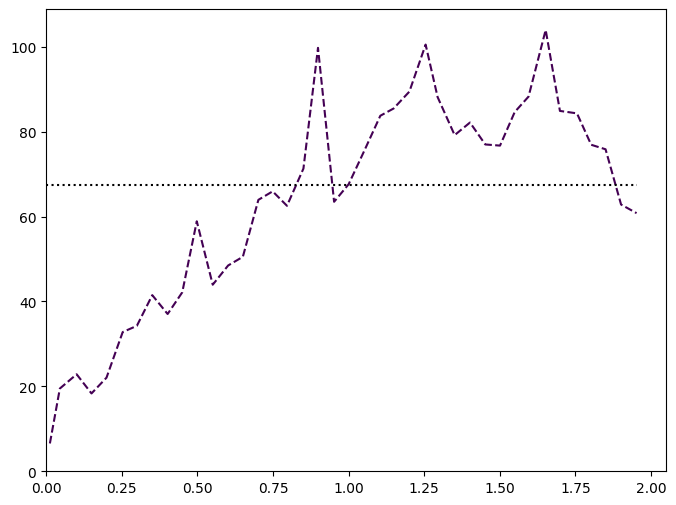

In [95]:
varioexp2residuals = mg.vario_exp(db_jura, vname= ["RESCO","RESNI"], nlag = 40, dlag = 0.05, toldis = 0.5)

# Plot experimental variograms
ax=gp.varmod(varioexp2residuals)

Fitting a model into the variogram of residuals before using it in kringing interpolation

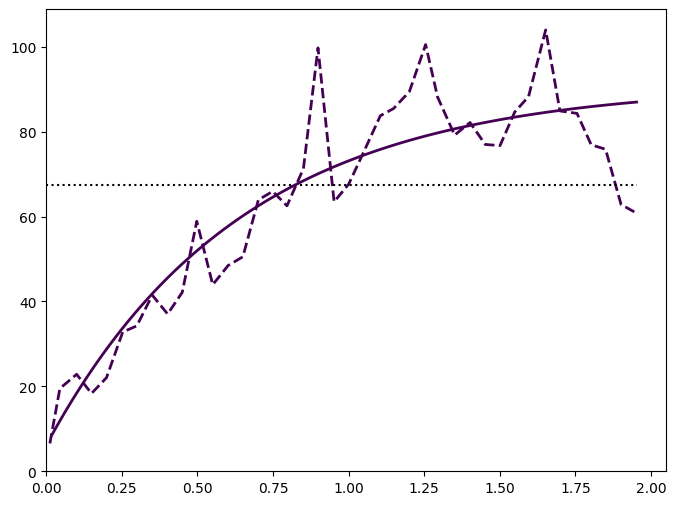

In [ ]:
fitmod2residuals = mg.model_fit(varioexp2residuals, struct =["NUGGET","SPHERICAL","EXPONENTIAL","CUBIC"],aniso_model = False)
ax = gp.varmod(varioexp2residuals, fitmod2residuals, lw=2)

CoKriging on residuals

In [ ]:
mg.minikriging(dbin=db_jura, dbout=db_grid, vname = ["RESCO","RESNI"], model=fitmod2residuals, prefix = "COKCONI")

In [105]:
print(db_grid)


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 23
Total number of samples      = 11349

Grid characteristics:
---------------------
Origin :      0.300     0.100
Mesh   :      0.050     0.050
Number :         97       117

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = Xloc - Locator = x1
Column = 2 - Name = Yloc - Locator = x2
Column = 3 - Name = Landuse - Locator = NA
Column = 4 - Name = Rock - Locator = NA
Column = 5 - Name = Rock_K - Locator = NA
Column = 6 - Name = Rock_P - Locator = NA
Column = 7 - Name = Rock_Q - Locator = NA
Column = 8 - Name = Rock_S - Locator = NA
Column = 9 - Name = Landuse_F - Locator = NA
Column = 10 - Name = Landuse_P - Locator = NA
Column = 11 - Name = Landuse_M - Locator = NA
Column = 12 - Name = Landuse_T - Locator = NA
Column = 13 - Name = COKCONI.Ni.estim - Locator = NA
Column = 14 - Name = COKCONI

Eventually, adding the external drifts to both metals to get the predictions , i had problems of dimension of F_grid , i couldn't evaluate the drift on the last points , itherfore couldn't finish computations ,i tried to split the data set but it didn't work , i'm commenting the code bellow to avoid errors.

In [ ]:
"""
grid1=grid.loc[:5500]
grid2=grid.loc[5500:]
db_grid1= mg.df_to_db(grid1, coord_names = ["Xloc", "Yloc"])
db_grid2=mg.df_to_db(grid2, coord_names = ["Xloc", "Yloc"])
print(db_grid1)

F_grid1=mg.eval_drift_matrix(db_grid1,pol_drift=1, ext_drift=["Landuse_F","Landuse_P","Landuse_M","Landuse_T","Rock_K","Rock_P","Rock_Q","Rock_S"])
F_grid2=mg.eval_drift_matrix(db_grid2,pol_drift=1, ext_drift=["Landuse_F","Landuse_P","Landuse_M","Landuse_T","Rock_K","Rock_P","Rock_Q","Rock_S"])

mean_on_the_grid1=F_grid1@beta
mean_on_the_grid2=F_grid2@beta
mean_on_the_grid = np.concatenate([mean_on_the_grid1,mean_on_the_grid2])
print(mean_on_the_grid2.shape)
"""



Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 20
Total number of samples      = 5501

Variables
---------
Column = 0 - Name = Xloc - Locator = x1
Column = 1 - Name = Yloc - Locator = x2
Column = 2 - Name = Landuse - Locator = NA
Column = 3 - Name = Rock - Locator = NA
Column = 4 - Name = Rock_K-1 - Locator = NA
Column = 5 - Name = Rock_K-2 - Locator = NA
Column = 6 - Name = Rock_K-3 - Locator = NA
Column = 7 - Name = Rock_P-1 - Locator = NA
Column = 8 - Name = Rock_P-2 - Locator = NA
Column = 9 - Name = Rock_P-3 - Locator = NA
Column = 10 - Name = Rock_Q-1 - Locator = NA
Column = 11 - Name = Rock_Q-2 - Locator = NA
Column = 12 - Name = Rock_Q-3 - Locator = NA
Column = 13 - Name = Rock_S-1 - Locator = NA
Column = 14 - Name = Rock_S-2 - Locator = NA
Column = 15 - Name = Rock_S-3 - Locator = NA
Column = 16 - Name = Landuse_F - Locator = NA
Column = 17 - Name = La

259
[-1.83853565e+16 -9.20439411e+15 -9.40225265e+15 -1.81352065e+16
 -1.80030988e+16 -1.85695962e+16 -1.84311587e+16 -1.84599417e+16
 -1.80906774e+16 -1.82254055e+16 -1.85563232e+16 -1.35846614e+16
 -1.85575685e+16 -1.35823623e+16 -1.80320793e+16 -1.85474827e+16
 -1.84571453e+16 -1.86038430e+16 -1.81249048e+16 -1.82866759e+16
 -1.81465243e+16 -9.33891307e+15 -1.82041683e+16 -9.64253310e+15
 -1.37302874e+16 -1.80642600e+16 -1.80325612e+16 -1.84414679e+16
 -1.41392621e+16 -1.81457184e+16 -9.58483406e+15 -1.85801652e+16
 -1.37702262e+16 -1.86057593e+16 -1.85334731e+16 -1.85484319e+16
 -1.80618666e+16 -1.84421609e+16 -9.39995359e+15 -9.03817990e+15
 -1.83879880e+16 -1.82626205e+16 -1.85322279e+16 -1.83612611e+16
 -9.47252692e+15 -1.85586223e+16 -9.04058111e+15 -1.36087568e+16
 -9.57446463e+15 -9.20187137e+15 -1.84083981e+16 -1.85797588e+16
  8.88514599e+15 -1.84829833e+16 -1.83345619e+16 -1.81167793e+16
 -1.83131103e+16 -1.80010461e+16 -1.36362449e+16 -1.82262830e+16
 -1.87054936e+16 -1.7

In [103]:
print(db_jura)


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 19
Total number of samples      = 259

Variables
---------
Column = 0 - Name = Xloc - Locator = x1
Column = 1 - Name = Yloc - Locator = x2
Column = 2 - Name = Landuse - Locator = NA
Column = 3 - Name = Rock - Locator = NA
Column = 4 - Name = Cd - Locator = NA
Column = 5 - Name = Co - Locator = NA
Column = 6 - Name = Cr - Locator = NA
Column = 7 - Name = Cu - Locator = NA
Column = 8 - Name = Ni - Locator = z1
Column = 9 - Name = Pb - Locator = NA
Column = 10 - Name = Zn - Locator = NA
Column = 11 - Name = Rock_K - Locator = NA
Column = 12 - Name = Rock_P - Locator = NA
Column = 13 - Name = Rock_Q - Locator = NA
Column = 14 - Name = Rock_S - Locator = NA
Column = 15 - Name = Landuse_F - Locator = NA
Column = 16 - Name = Landuse_P - Locator = NA
Column = 17 - Name = Landuse_M - Locator = NA
Column = 18 - Name = Landus

In [ ]:
"""result= mean_on_the_grid+ db_grid["COKCONI.CO.estim"]
print(result)
"""

ValueError: operands could not be broadcast together with shapes (5957,) (11349,0) 

In [ ]:
'''
ext_drift_vars = rock_newnames + lu_newnames  # defined earlier in the notebook
varioResiduals = mg.vario_exp(db_jura, vname=["Co", "Ni"], ext_drift=ext_drift_vars,
                             nlag=30, dlag=0.1, toldis=0.5)
ax = gp.varmod(varioResiduals,showPairs=False,color = "r",label = "Residual")
'''

In [ ]:
import statsmodels.api as sm

ext_drift_vars = newnames

# Fit linear model for Co and Ni on drift indicators and store residuals
X = sm.add_constant(jura[ext_drift_vars])
ols_co = sm.OLS(jura['Co'], X).fit()
jura['Co_resid'] = jura['Co'] - ols_co.fittedvalues

ols_ni = sm.OLS(jura['Ni'], X).fit()
jura['Ni_resid'] = jura['Ni'] - ols_ni.fittedvalues

# Update / recreate gstlearn Db (so db_jura contains the new columns)
db_jura = mg.df_to_db(jura, coord_names=['Xloc','Yloc'])

# Variograms and covariogram of residuals
vario_res_2var = mg.vario_exp(db_jura, vname=['Co_resid','Ni_resid'],
                               nlag=30, dlag=0.1, toldis=0.5)
vario_res_2var.compute(db_jura)
gp.varmod(vario_res_2var)

Let's now fit a model.

## V. Maximum Likelihood estimation (using minigst)

1. Compute the maximum likelihood estimator of the parameters of (some of) your favorite univariate model(s) for the Cobalt concentration.
2. Compare the models through a likelihood ratio test or by computing the AIC if they are not nested.
3. Compute the predictions for each model.

## Implementation of the maximum likelihood estimation

**1 Likelihood estimation of the drift and covariance matrix in the **

**1.1 Isotropic setup (Exponential and gaussian models)**

In [ ]:
## Empirical variogram approach
varioexp = mg.vario_exp(db_jura,vname="Co",nlag=30, dlag=0.1, toldis = .5)
struct_names = ["EXPONENTIAL"] #Use only one structure
struct_names2 =["GAUSSIAN"]
# isotropic case
model_iso=mg.model_fit(varioexp,struct=struct_names)
model_iso_gaussiène=mg.model_fit(varioexp, struct= struct_names2)

gp.varmod(varioexp, model_iso)

**Here we define the likelihood function.**



In [ ]:
def neg_log_likelihood(db,vname,model, pol_drift = 0, ext_drift = []):

    C = mg.eval_cov_matrix(model,db)
    F = mg.eval_drift_matrix(db,pol_drift, ext_drift)
    ndat = C.shape[0]
    z = db[vname]



    invC = np.linalg.inv(C)
    beta = np.linalg.inv(F.T@invC@F) @ (F.T@invC@z)

    betavect = np.atleast_1d(beta) # make beta a vector (in case where a single value is given)

    logdet = np.linalg.slogdet(C)[1] # log determinant

    Zc = z-F@betavect #Centered bvector
    Cm1Zc = np.linalg.solve(C,Zc)
    quad = Zc.T@Cm1Zc #Quadratic term
    ###############################
    return .5 * (logdet + quad) + ndat/2 * np.log(2. * np.pi)

In [ ]:
import scipy as sc

### Optimization with scipy.optimize.minimize

We create a function with first argument, the vector of model parameters [sigma, range]

In [ ]:
def neg_log_likelihood_for_optim(params,db,vname,model, pol_drift = None, ext_drift = []):
    sigma2 = params[0]**2
    theta = np.abs(params[1])
    mg.set_sill(model,  sigma2)
    mg.set_range(model, theta)
    result = neg_log_likelihood(db,vname,model,pol_drift,ext_drift)
    print("sill " +        str(np.round(sigma2,2)) +
          " range " +      str(np.round(theta,2)) +
          " likelihood " + str(-np.round(result,2)))
    return result

def fitMLE(params,db,vname,model, pol_drift = None, ext_drift = []):
    bds = ((0.00001,10),(0.00001,10))
    res =  sc.optimize.minimize(neg_log_likelihood_for_optim,params,
                                args = (db,vname,model,pol_drift,ext_drift),
                                bounds= bds)
    print("Optimisation finished")
    return res
model_exponential = mg.create_model("EXPONENTIAL")
result_exponential = mg.model_mle(db_jura,"Co",struct = ["NUGGET","EXPONENTIAL"],aniso_model = False)

### Gaussian model for the covariance matrix

In [ ]:
model_gaussian = mg.create_model("GAUSSIAN")
fitMLE(np.array([1,0.1]),db_jura,"Co",model_exponential)
fitMLE(np.array([1,0.1]),db_jura,"Co",model_exponential)
fitMLE(np.array([8,0.5]),db_jura,"Co",model_gaussian)
result_gaussian = mg.model_mle(db_jura,"Co",struct = ["GAUSSIAN"],aniso_model = False)

The result of the optimization for the gaussian model seems a bit surprising : $C(h)= C(0) \delta _0(h)$ (nugget). An other remark is that the minimum obtained depends on the initial configuration (Maybe the algorithm can return a local minimum), We try bellow another initial configuration.

In [ ]:
fitMLE(np.array([4,1.5]),db_jura,"Co",model_exponential)

In [ ]:
gp.plot(model_exponential,label="Maximum Likelihood_(exponential_setup)",color="r")
gp.plot(model_gaussian,label="Maximum Likelihood_(gaussian_setup)",color="gray")
gp.plot(varioexp,label="Empirical", color = "blue")
gp.plot(model_iso,label="Automatic fitting")
#gp.plot(result["model"],label="minigst",color = "green")
aa=plt.legend()


In [ ]:
model_gaussian = mg.create_model("GAUSSIAN")

fitMLE(np.array([3.5,1]),db_jura,"Co",model_gaussian)
result_gaussian = mg.model_mle(db_jura,"Co",struct = ["GAUSSIAN"],aniso_model = False)

In [ ]:
gp.plot(model_exponential,label="Maximum Likelihood_(exponential_setup)",color="r")
gp.plot(model_gaussian,label="Maximum Likelihood_(gaussian_setup)",color="gray")
gp.plot(varioexp,label="Empirical", color = "blue")
gp.plot(model_iso,label="Automatic fitting")
#gp.plot(result["model"],label="minigst",color = "green")
aa=plt.legend()


We obtain this time a more "expected" result . A possible approach in this context is to try some interesting and far initial configurations and choose the best one.

**2 Comparing kriging's results** based on  three estimations of the covariance matrix , first on the two estimations in the exponential model (automatic fitting and MLE) , then between the MLE of the exponential model and MLE of the gaussian model.

In [ ]:
result_exponential["model"]

In [ ]:
mg.del_var_from_db(db_val,["MLE*"])
mg.del_var_from_db(db_val,["VARIO*"])

## Compute kriging (warning to the order of vname which has to be identical to one provided to the vario_exp function
mg.minikriging(dbin=db_jura, dbout=db_val, vname = "Co", model=result_exponential["model"], prefix = "MLE_Exponential")
mg.minikriging(dbin=db_jura, dbout=db_val, vname = "Co", model=result_gaussian["model"], prefix = "MLE_Gaussian")

## Compute RMSE
rmse_MLE=np.mean((val["Co"]-db_val["MLE_Exponential.Co.estim"])**2)**0.5
print("RMSE MLE EXPONENTIAL=",rmse_MLE)

## Compute MAPE
mape_MLE=np.mean(abs((val["Co"]-db_val["MLE_Exponential.Co.estim"])/val["Co"]))
print("MAPE MLE EXPONENTIAL=",mape_MLE)

mg.minikriging(dbin=db_jura, dbout=db_val, vname = "Co", model=model_iso, prefix = "VARIO")

## Compute RMSE
rmse_VARIO=np.mean((val["Co"]-db_val["VARIO.Co.estim"])**2)**0.5
print("RMSE VARIO=",rmse_VARIO)

## Compute MAPE
mape_VARIO=np.mean(abs((val["Co"]-db_val["VARIO.Co.estim"])/val["Co"]))
print("MAPE VARIO=",mape_VARIO)


**Comments**
For the exponential model , MLE seems to be a better estimator of the covariance matrix.

**Comparing performances between MLE's**

In [ ]:
## Compute RMSE
rmse_MLE=np.mean((val["Co"]-db_val["MLE_Exponential.Co.estim"])**2)**0.5
print("RMSE MLE EXPONENTIAL=",rmse_MLE)

## Compute MAPE
mape_MLE=np.mean(abs((val["Co"]-db_val["MLE_Exponential.Co.estim"])/val["Co"]))
print("MAPE MLE EXPONENTIAL=",mape_MLE)

## Compute RMSE
rmse_MLE=np.mean((val["Co"]-db_val["MLE_Gaussian.Co.estim"])**2)**0.5
print("RMSE MLE Gaussian=",rmse_MLE)

## Compute MAPE
mape_MLE=np.mean(abs((val["Co"]-db_val["MLE_Gaussian.Co.estim"])/val["Co"]))
print("MAPE MLE Gaussian=",mape_MLE)



Incase we want to estimate the parameters using MLE , the exponential model seems better.


## VI. Conditional simulations (using minigst)

The information threshold for the concentration of cobalt in soils is *12 mg/kg*.

1. Generate 100 conditional simulations of the Cobalt concentrations over the swiss Jura according to your favorite model.
2. Compute the mean surface of the area of exceedance as well as its associated centered 95% confidence interval.
3. Compute and plot the exceedance probability map. Do you actually need simulations to produce it? Comment.

In [ ]:
import gstlearn as gl
import gstlearn.plot as gp
import minigst as mg

## Dataset
jura, grid, _ = mg.data("Jura")



First we need a model and a grid:

In [ ]:
## Create Db containing the training data
db_jura=mg.df_to_db(jura,["Xloc","Yloc"])
## Create experimental variogram
varioexp = mg.vario_exp(db_jura, vname = "Co",nlag=30, dlag=0.1, toldis=0.5)

## Fit experimental variogram with an exponential covariance
types = ["EXPONENTIAL"]
fitmod = mg.model_fit(varioexp,struct=types)

## Create DbGrid that covers the Db containing the data
db_grid= mg.df_to_dbgrid(grid, ["Xloc","Yloc"])

In [ ]:
mg.simulate_gauss_rf(db_grid, fitmod, nsim=100,dbcond=db_jura, vcond="Co")
db_grid.display()

In [ ]:
## Plot conditional Simulation
im=gp.plot(db_grid, "Simu.Co.98")
gp.plot(db_jura, c='black',s=1)
plt.title("Conditional Gaussian Random Field Simulation")
plt.axis("equal")
plt.colorbar(im)
plt.show()

**mean surface of the area of exceedance**

To **estimate** the surface of exceedance , we multiply the proportion of the points of exceedance by the total area.

In [ ]:
record_of_number_of_points_of_exceedance=[]
xmax=grid["Xloc"].max()
xmin=grid["Xloc"].min()
ymax=grid["Yloc"].max()
ymin=grid["Yloc"].min()
N=len(grid['Xloc'])
for i in range(100):
     db_grid_i= np.array(db_grid[f"Simu.Co.{i+1}"])
     number_of_points_of_exceedance= len(db_grid_i[db_grid_i>12])
     record_of_number_of_points_of_exceedance.append(number_of_points_of_exceedance)
print([db_grid[f"Simu.Co.5"]>12])
global_surface=(xmax-xmin)*(ymax-ymin)
mean_surface=np.mean(np.array(record_of_number_of_points_of_exceedance))/N*global_surface
print(global_surface)
print(mean_surface)

#print(number_of_points_of_exceedance)

The estimated surface of exceedance is slightly lower than half of the global surface.

**Confidence interval**


To compute a confidence interval (in this context) , i didn't find a simple way to express the law of the surface of exceedance. We propose to use the following appriximation (motivated by the central limit theorem). $\frac{SE-μ}{\sigma}$~ $N(0,1)$. In fact , using a T-student distribution would probably be more precise since σ itself is estimated, but we use the previuos formula.

In [ ]:
std_estimmation= np.std(np.array(record_of_number_of_points_of_exceedance))
quantile_95=sc.stats.norm.ppf(0.95)
print(std_estimmation)
print(quantile_95)

**Probability of exceedance map**
It might be enough to use the quantile function (in $ℝ^N$ , $N$ being the number of points) , since that the law of the remaining points (conditionned by the known points) is gaussian (with a known quantile function once centered and scaled)

## VII. Summary -- Discussion

## Appendix:
Description of the predictions submitted on kaggle (models, parameters) and corresponding prediction maps.


We will now train our models on the entire dataset and predict on the Kaggle validation locations (*val_loc_k*).
In order to do that, we will first change the *Landuse* and *Rock* values by their str counterparts.

In [ ]:
val_loc_k["Landuse"]=val_loc_k["Landuse"].replace(landuse_codes,landuse_names)
val_loc_k["Rock"]=val_loc_k["Rock"].replace(rock_codes,rock_names)

### Random Forests

We optimize the parameters of this random forests model using *RandomizedSearchCV* (less costly than *SearchGrid*). During the cross-validation, we use *KMeans* clustering to define groups of points to avoid spatial overfitting.

In [ ]:
## Random forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint
import os

#Optimization of hyperparameters
param_dist = {
    'n_estimators': randint(100, 1000),
    'max_depth': [None] + list(range(5, 31, 5)),
    'min_samples_split': randint(2, 11),
    'min_samples_leaf': randint(1, 5),
    'max_features': ['auto', 'sqrt', 0.3, 0.5, 0.8]
}

# Avoid KMeans/MKL memory leak on Windows by limiting OpenMP threads
os.environ.setdefault("OMP_NUM_THREADS", "2")

coords = jura_all[['Xloc','Yloc']].to_numpy()
n_groups = 10
kmeans = KMeans(n_clusters=n_groups, random_state=0).fit(coords)
groups = kmeans.labels_

gkf = GroupKFold(n_splits=5)

rf = RandomForestRegressor(random_state=0)

rs = RandomizedSearchCV(rf, param_distributions=param_dist, n_iter=50,
                        scoring='neg_mean_squared_error', cv=gkf.split(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'], groups=groups), n_jobs=-1, random_state=0, verbose=2)
rs.fit(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'])
best_rf = rs.best_estimator_

## Fit model
best_rf.fit(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'])

## Prediction on the grid
res_rf = best_rf.predict(grid[['Xloc','Yloc'] + newnames])
## Plot results
plot_grid_variable(res_rf, grid, "Co.pred.rf")
plt.show()

## Prediction on the Kaggle validation locations
res_val_rf = best_rf.predict(val_loc_k[['Xloc','Yloc'] + newnames])

to_kaggle = pd.DataFrame({"V1" : range(1,val_loc_k.shape[0]+1), "V2" : res_val_rf})
to_kaggle.to_csv('submission_rf.csv',index=False)

#### Gradient Boosting Tress (XGBoost)

We do the same but with XGBoostRegressor instead of RandomForestRegressor.

In [ ]:
# XGBoost regression
from xgboost import XGBRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint
import os

# Optimization of hyperparameters
param_dist_xgb = {
    'n_estimators': randint(100, 1000),
    'max_depth': [3, 5, 7, 9, 12],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'subsample': [0.5, 0.7, 0.9, 1.0],
    'colsample_bytree': [0.3, 0.5, 0.7, 1.0],
    'min_child_weight': randint(1, 10),
    'gamma': [0, 0.1, 0.2, 0.5, 1.0]
}

# Avoid KMeans/MKL memory leak on Windows by limiting OpenMP threads
os.environ.setdefault("OMP_NUM_THREADS", "1 ")

coords = jura_all[['Xloc','Yloc']].to_numpy()
n_groups = 10
kmeans = KMeans(n_clusters=n_groups, random_state=0).fit(coords)
groups = kmeans.labels_

gkf = GroupKFold(n_splits=5)

xgb = XGBRegressor(objective='reg:squarederror', random_state=0, n_jobs=-1, verbosity=0)

rs_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring='neg_mean_squared_error',
    cv=gkf.split(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'], groups=groups),
    n_jobs=-1,
    random_state=0,
    verbose=2
)

# Tune
rs_xgb.fit(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'])
best_xgb = rs_xgb.best_estimator_

# Fit best model
best_xgb.fit(jura_all[['Xloc','Yloc'] + newnames], jura_all['Co'])

# Predict on grid and plot
res_xgb = best_xgb.predict(grid[['Xloc','Yloc'] + newnames])
plot_grid_variable(res_xgb, grid, "Co.pred.xgb")
plt.show()

## Prediction on the Kaggle validation locations
res_val_xgb = best_xgb.predict(val_loc_k[['Xloc','Yloc'] + newnames])

to_kaggle = pd.DataFrame({"V1" : range(1,val_loc_k.shape[0]+1), "V2" : res_val_xgb})
to_kaggle.to_csv('submission_xgb.csv',index=False)

In [ ]:
db_val=mg.df_to_db(val_loc_k, ["Xloc","Yloc"])
mg.minikriging(dbin=db_jura, dbout=db_val, vname = "Co", model=result_gaussian["model"], prefix = "MLE_Gaussian")
print(db_val["MLE_Exponential.Co.estim"])
print(val_loc_k.shape[0])
to_kaggle = pd.DataFrame({"V1" : range(1,val_loc_k.shape[0]+1), "V2" : db_val["MLE_Gaussian.Co.estim"]})
to_kaggle.to_csv('submission_gaussian_MLE.csv',index=False)